# 初期平均フォノン数と誤差生成子の主要10項
角度校正前で保存した CPTP 射影済みの $\chi$ 行列を使い、各 $\bar n$ で Pauli transfer matrix の対数を H/S/C/A 基底に分解する。指定の5項を含め、残り5項は校正前のスイープ全体での最大絶対値が大きい順に選ぶ。表と図は選んだ10項を同じ基準で降順に並べ、値の符号を保持する。

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.linalg import logm
import numpy as np

from drive_calibration_qpt_analysis import _chi_raw_to_superoperator
from ms_gate_functions import superoperator_to_ptm
from noise_error_structure import _decompose_generator_taxonomy

source = Path("results/calibration_channel_comparison/projected_chi_before_after.npz")
records = []
with np.load(source) as data:
    chis = data["chi_before"]
    nbars = data["n_bar"]
    if len(chis) != len(nbars):
        raise ValueError("Unexpected number of pre-calibration channels")
    for nbar, chi in zip(nbars, chis):
        # 保存された trace-one χ を QuTiP の2量子ビット規約に戻す。
        channel = _chi_raw_to_superoperator(16 * chi)
        generator = logm(superoperator_to_ptm(channel)).real
        fit = _decompose_generator_taxonomy(generator)
        for (sector, mode), value in zip(fit["metadata"], fit["coefficients"]):
            records.append((nbar, f"{sector}:{mode}", value))

values = pd.DataFrame(records, columns=["n_bar", "term", "value"])
sweep = values.pivot(index="term", columns="n_bar", values="value").sort_index(axis=1)

In [9]:
required = ["H:XX", "S:XX", "S:IX", "S:XI", "C:IX,XI"]
peak = sweep.abs().max(axis=1)
extra = peak.drop(required).nlargest(5).index.tolist()
order = peak.loc[required + extra].sort_values(ascending=False, kind="stable").index
summary = sweep.loc[order].copy()
summary.insert(0, "max |coefficient|", peak.loc[order])
summary.style.format("{:.4e}").set_caption("校正前の係数（1ゲートあたり）と初期平均フォノン数")

n_bar,max |coefficient|,0.010000,1.000000,2.000000,4.000000,6.000000,8.000000,10.000000
term,,,,,,,,
H:XX,1.5244e-01,1.3736e-02,2.8806e-02,4.3740e-02,7.2711e-02,1.0046e-01,1.2702e-01,1.5244e-01
S:XX,1.8698e-02,1.6386e-04,6.1588e-04,1.4847e-03,4.2931e-03,8.2741e-03,1.3153e-02,1.8698e-02
S:XI,4.6679e-03,5.5061e-04,1.0704e-03,1.5667e-03,2.4762e-03,3.2901e-03,4.0178e-03,4.6679e-03
S:IX,4.6679e-03,5.5061e-04,1.0704e-03,1.5667e-03,2.4762e-03,3.2901e-03,4.0178e-03,4.6679e-03
"C:IX,XI",4.6429e-03,5.2562e-04,1.0454e-03,1.5417e-03,2.4512e-03,3.2651e-03,3.9928e-03,4.6429e-03
S:IZ,1.7451e-04,1.7451e-04,1.5044e-04,1.4392e-04,1.3862e-04,1.3613e-04,1.3461e-04,1.3353e-04
S:ZI,1.7451e-04,1.7451e-04,1.5044e-04,1.4392e-04,1.3862e-04,1.3614e-04,1.3462e-04,1.3352e-04
S:YX,1.7450e-04,1.7450e-04,1.5042e-04,1.4390e-04,1.3860e-04,1.3604e-04,1.3450e-04,1.3348e-04
S:XY,1.7450e-04,1.7450e-04,1.5042e-04,1.4391e-04,1.3861e-04,1.3606e-04,1.3451e-04,1.3349e-04


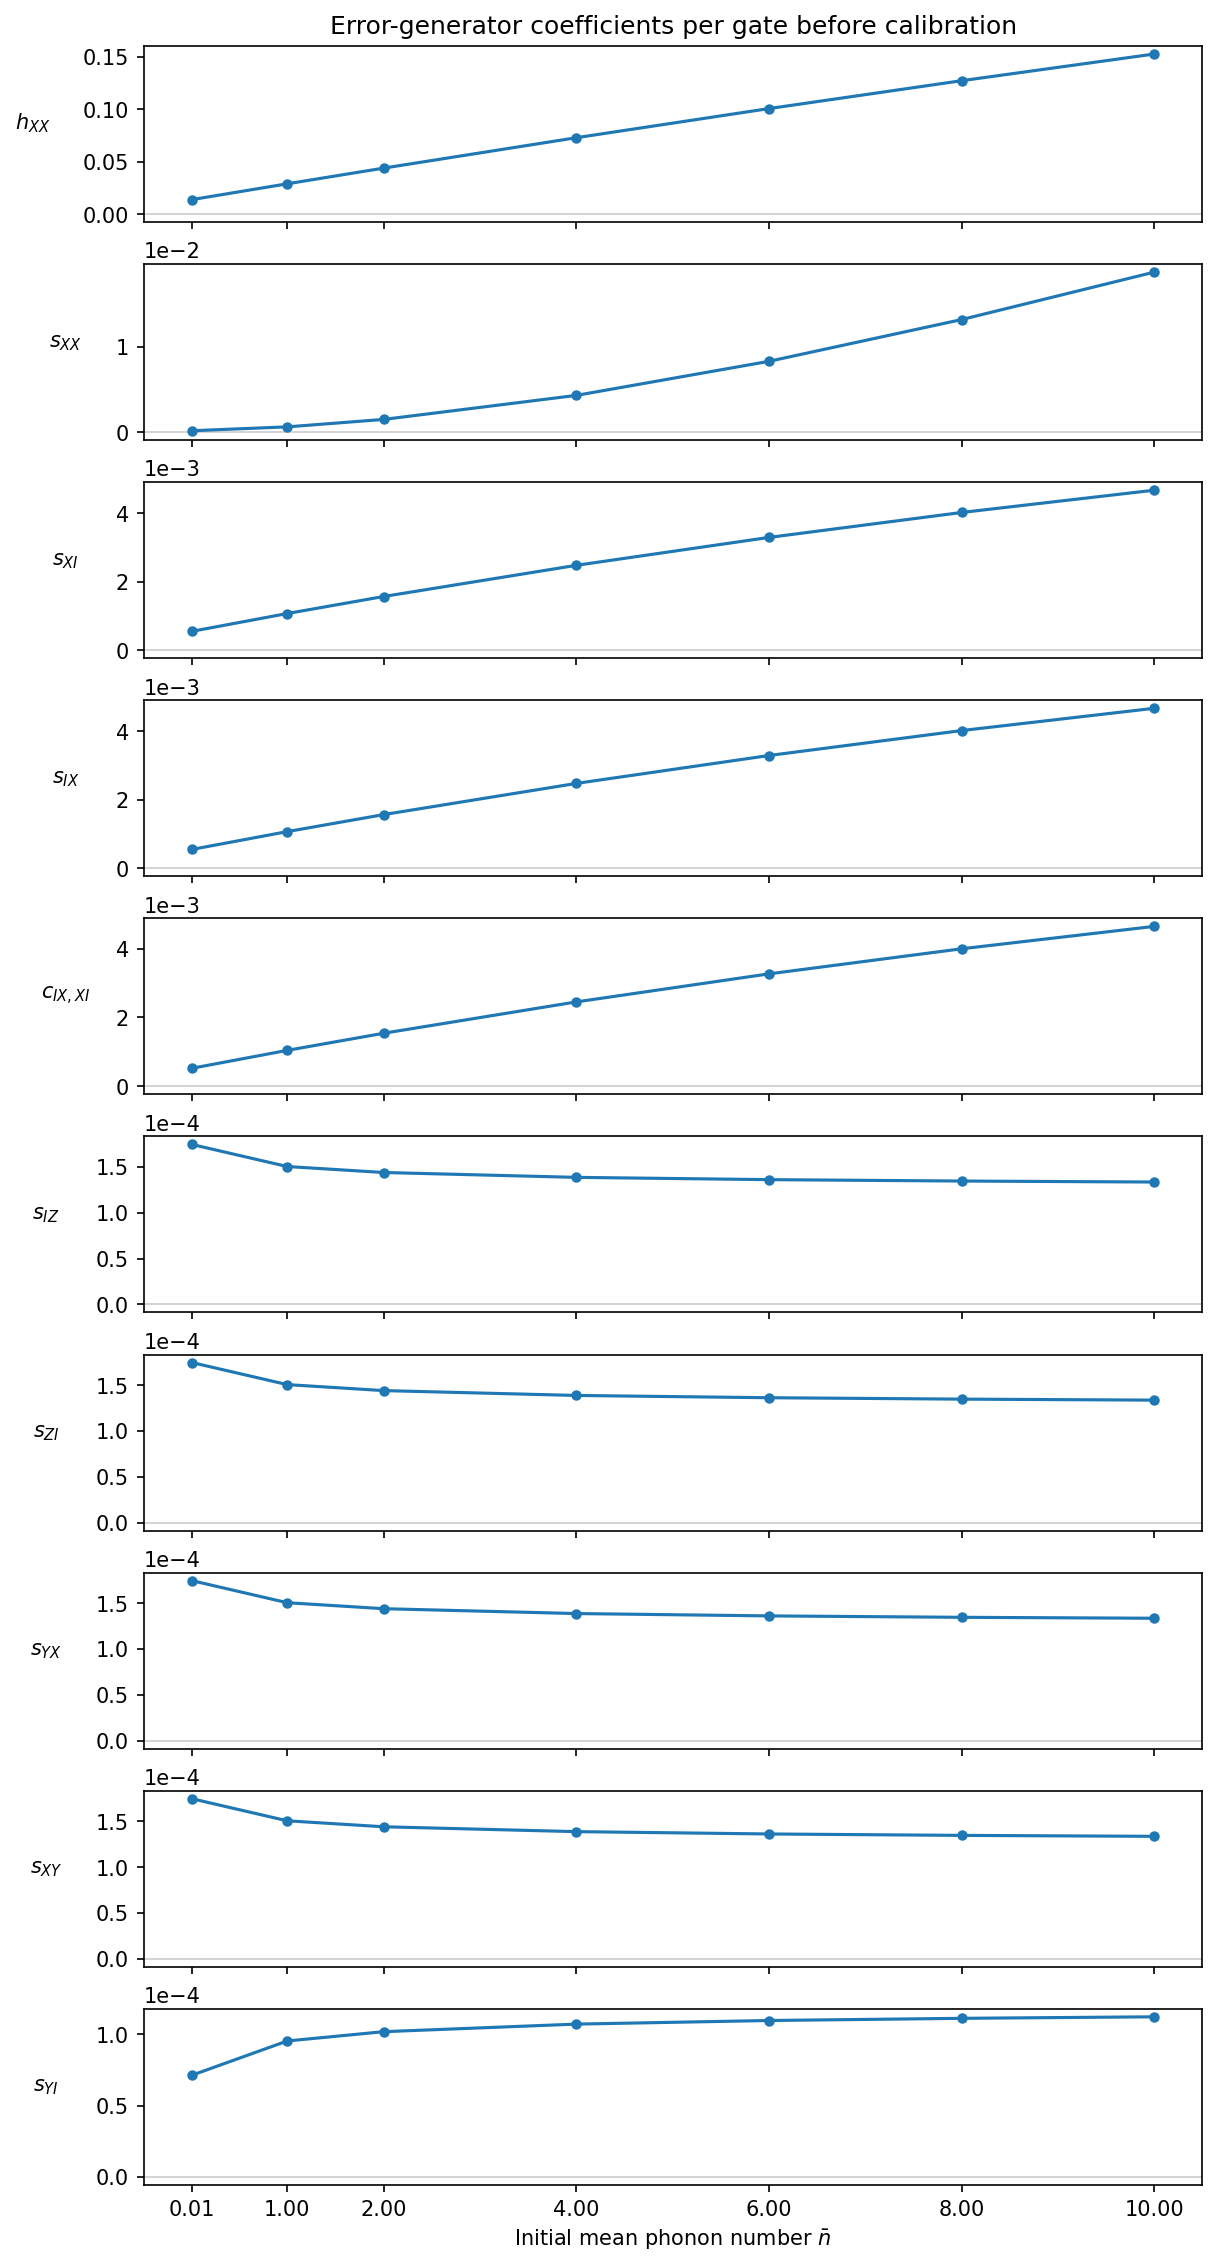

In [11]:
fig, axes = plt.subplots(len(order), 1, figsize=(8, 15), sharex=True, layout="constrained")
for ax, term in zip(axes, order):
    sector, mode = term.split(":")
    ax.set_ylabel(rf"$ {sector.lower()}_{{{mode}}} $", rotation=0, labelpad=24)
    ax.axhline(0, color="0.8", lw=0.8)
    series = sweep.loc[term]
    ax.plot(series.index, series, "o-", ms=4)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
axes[0].set_title("Error-generator coefficients per gate before calibration")
axes[-1].set_xlabel(r"Initial mean phonon number $\bar n$")
axes[-1].set_xticks(sweep.columns)
output_path = source.with_name("generator_top10_nbar.png")
fig.savefig(output_path, dpi=150, bbox_inches="tight")
plt.close(fig)
from IPython.display import Image, display
display(Image(filename=str(output_path), width=800))
print(output_path.resolve())

## 校正前の平均ゲート infidelity と主要5係数
各列で指定したノイズだけを ON にし、全 OFF と比較する。最上段は CPTP 射影後の完全なチャネルから求める平均ゲート infidelity。下の5段は指定した生成子係数。

In [12]:
# "all" で4種類を表示。1種類に絞るには下のキーを指定する。
NOISE_NAME = "all"
noise_titles = {
    "motional_heating": "Motional heating",
    "motional_dephasing": "Motional dephasing",
    "spin_dephasing": "Spin dephasing",
    "photon_scattering": "Photon scattering",
}
if NOISE_NAME != "all" and NOISE_NAME not in noise_titles:
    raise ValueError(f"Choose 'all' or one of {list(noise_titles)}")
selected = list(noise_titles) if NOISE_NAME == "all" else [NOISE_NAME]

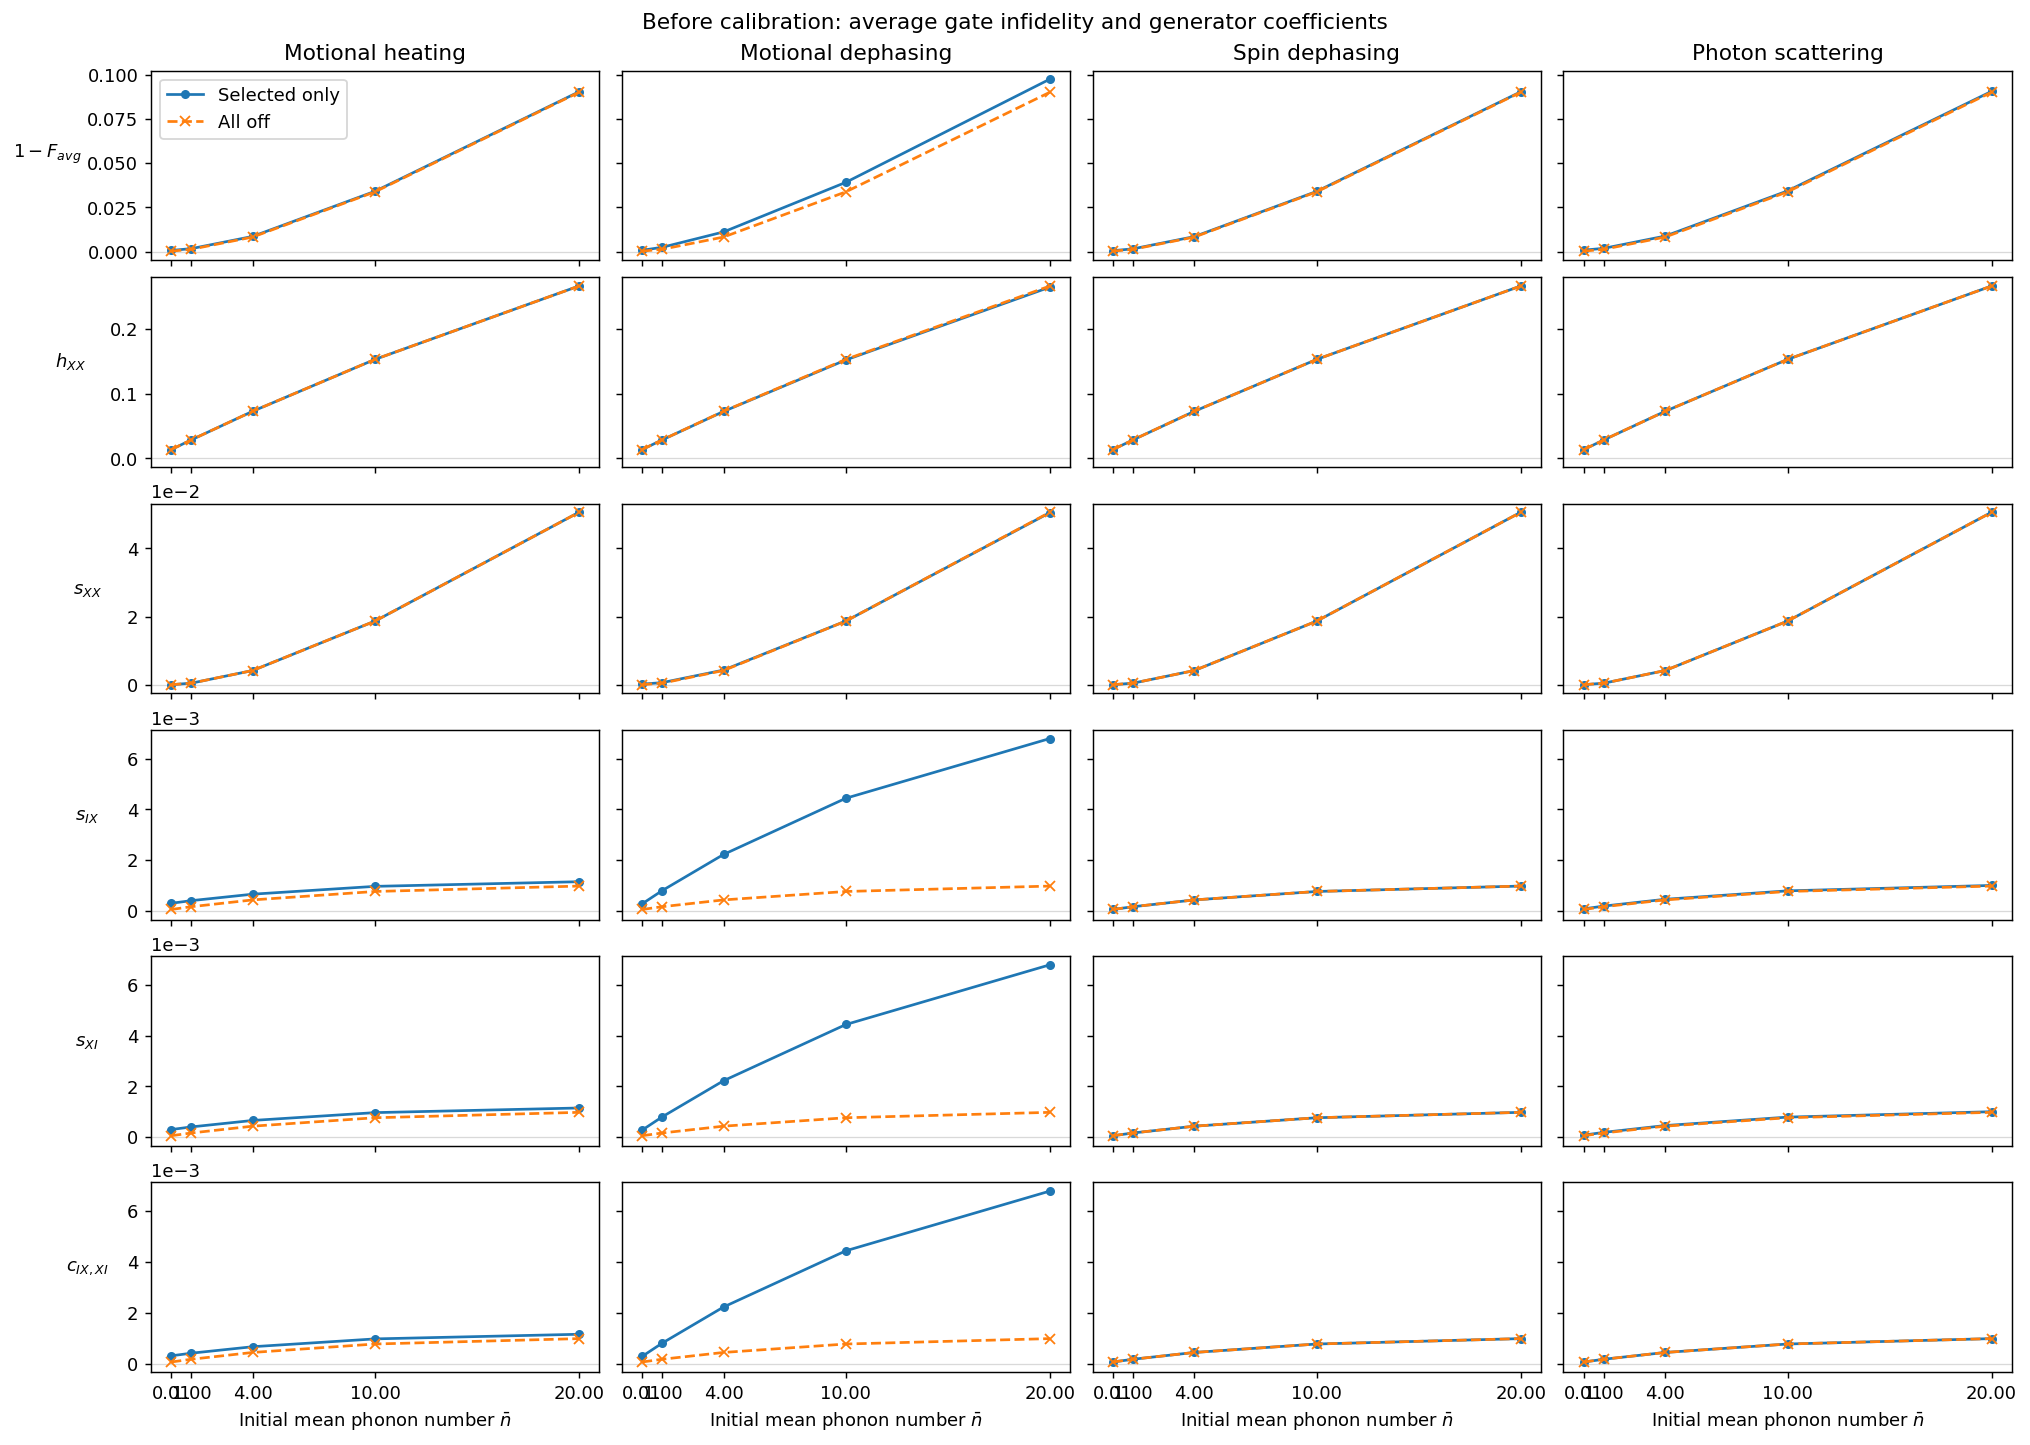

In [13]:
from drive_calibration_qpt_analysis import project_trace_normalized_chi_to_cptp

cache = Path("results/chi_error_element_fit/noise_source_ablation")

def read_sweep(condition):
    rows = {}
    for path in sorted(cache.glob(f"{condition}__nbar_*.npz")):
        with np.load(path) as data:
            nbar = float(data["n_bar"].item())
            channel, projected_chi, _ = project_trace_normalized_chi_to_cptp(data["chi_trace_normalized"])
        fit = _decompose_generator_taxonomy(logm(superoperator_to_ptm(channel)).real)
        rows[nbar] = {f"{s}:{m}": v for (s, m), v in zip(fit["metadata"], fit["coefficients"])}
        rows[nbar]["infidelity"] = 4 / 5 * (1 - projected_chi[0, 0].real)
    if not rows:
        raise FileNotFoundError(f"No saved channels for {condition} in {cache}")
    return pd.DataFrame.from_dict(rows, orient="index").sort_index()

off = read_sweep("none")
metrics = ["infidelity", *required]
fig, axs = plt.subplots(len(metrics), len(selected), squeeze=False, sharex=True, sharey="row",
                        figsize=(1.5 + 3.5 * len(selected), 11), layout="constrained")
for col, noise in enumerate(selected):
    on = read_sweep(f"only__{noise}")
    if not on.index.equals(off.index):
        raise ValueError(f"ON/OFF phonon grids differ for {noise}")
    axs[0, col].set_title(noise_titles[noise])
    for row, term in enumerate(metrics):
        ax = axs[row, col]
        ax.axhline(0, color="0.85", lw=0.7)
        ax.plot(on.index, on[term], "o-", ms=4, label="Selected only")
        ax.plot(off.index, off[term], "x--", ms=5, label="All off")
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
        if col == 0 and term == "infidelity":
            ax.set_ylabel(r"$1-F_{avg}$", rotation=0, labelpad=22)
        elif col == 0:
            sector, mode = term.split(":")
            ax.set_ylabel(rf"${sector.lower()}_{{{mode}}}$", rotation=0, labelpad=22)
    axs[-1, col].set_xticks(on.index)
    axs[-1, col].set_xlabel(r"Initial mean phonon number $\bar n$")
axs[0, 0].legend()
fig.suptitle("Before calibration: average gate infidelity and generator coefficients")
comparison_path = source.with_name(f"infidelity_and_isolated_noise_{NOISE_NAME}.png")
fig.savefig(comparison_path, dpi=130, bbox_inches="tight")
plt.close(fig)
from IPython.display import Image, display
display(Image(filename=str(comparison_path)))

## 単独ノイズの強度依存性
他の3種類は OFF。各曲線は同じ初期占有数の全 OFF との差。

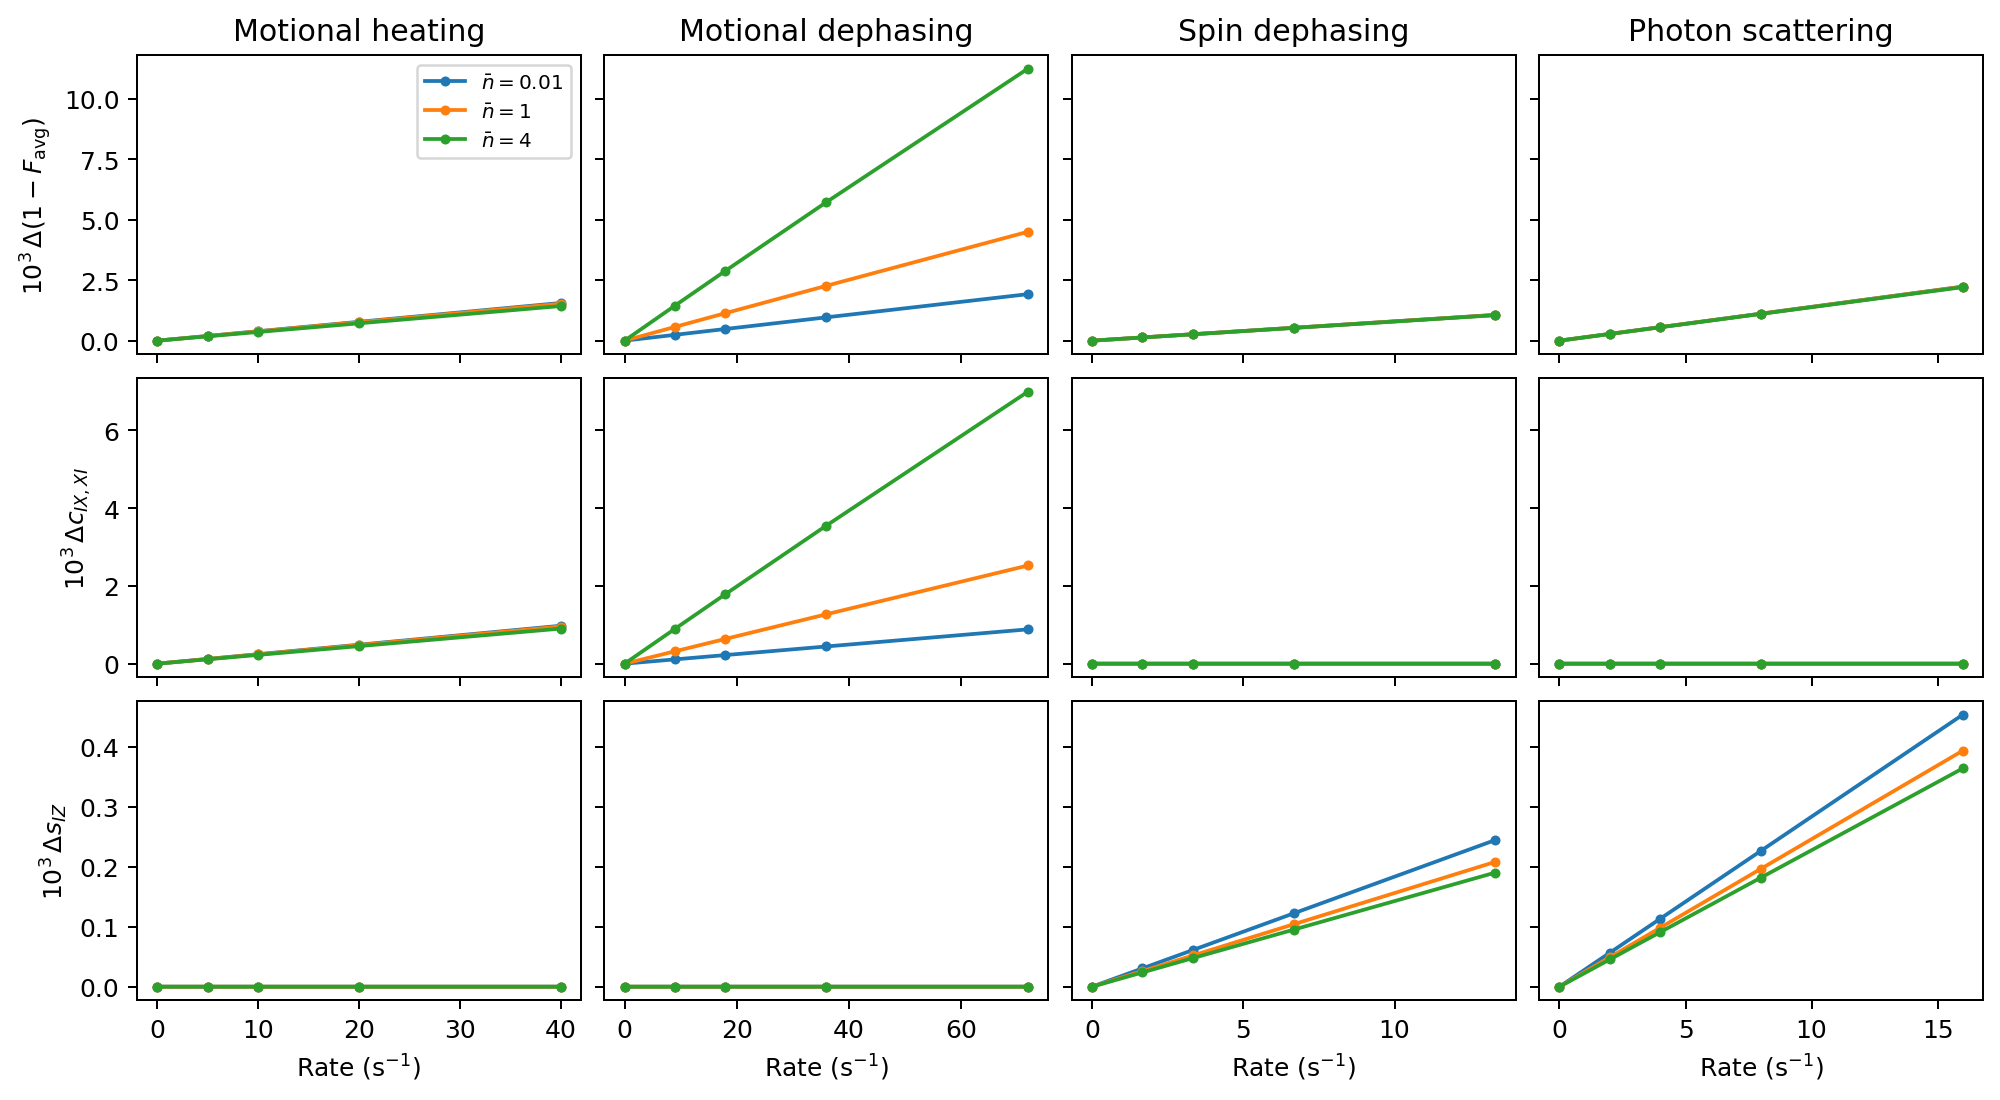

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

rates = pd.read_csv("results/rate_hsca_structure/rate_hsca_coefficients.csv")
channels = pd.read_csv("results/error_generator_rate_nbar/top3_pairwise_generator/pairwise_generator_summary.csv")
sources = ["motional_heating", "motional_dephasing", "spin_dephasing", "photon_scattering"]
occupations = [0.01, 1, 4]
fig, axes = plt.subplots(3, 4, sharex="col", sharey="row", figsize=(11, 6), layout="constrained")
for col, noise in enumerate(sources):
    axes[0, col].set_title(noise.replace("_", " ").capitalize())
    other_rates = [f"{key}_s^-1" for key in sources if key != noise]
    isolated = channels[channels[other_rates].eq(0).all(axis=1)]
    for nbar in occupations:
        subset = rates[(rates.noise_source == noise) & (rates.nbar == nbar)]
        coeff = subset.pivot(index="rate_s^-1", columns=["sector", "mode"], values="coefficient_per_gate").sort_index()
        loss = isolated[isolated.nbar == nbar].set_index(f"{noise}_s^-1")["average_infidelity"].loc[coeff.index]
        for ax, values in zip(axes[:, col], [loss - loss.loc[0], coeff["C", "IX,XI"], coeff["S", "IZ"]]):
            ax.plot(coeff.index, 1000 * values, "o-", ms=3, label=rf"$\bar n={nbar:g}$")
    axes[-1, col].set_xlabel(r"Rate ($\mathrm{s}^{-1}$)")
for ax, label in zip(axes[:, 0], [r"$10^3\,\Delta(1-F_{\rm avg})$", r"$10^3\,\Delta c_{IX,XI}$", r"$10^3\,\Delta s_{IZ}$"]):
    ax.set_ylabel(label)
axes[0, 0].legend(fontsize=8)
target = Path("figures/isolated_noise_strength")
target.parent.mkdir(exist_ok=True)
for ext in [".pdf", ".png"]:
    fig.savefig(target.with_suffix(ext), dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(target.with_suffix(".png"))))


## 2種類のノイズ強度とインフィデリティの非加算性
他の2種類は OFF。両方 ON の値から各単独 ON の値を引き、全 OFF の値を足して基準をそろえる。

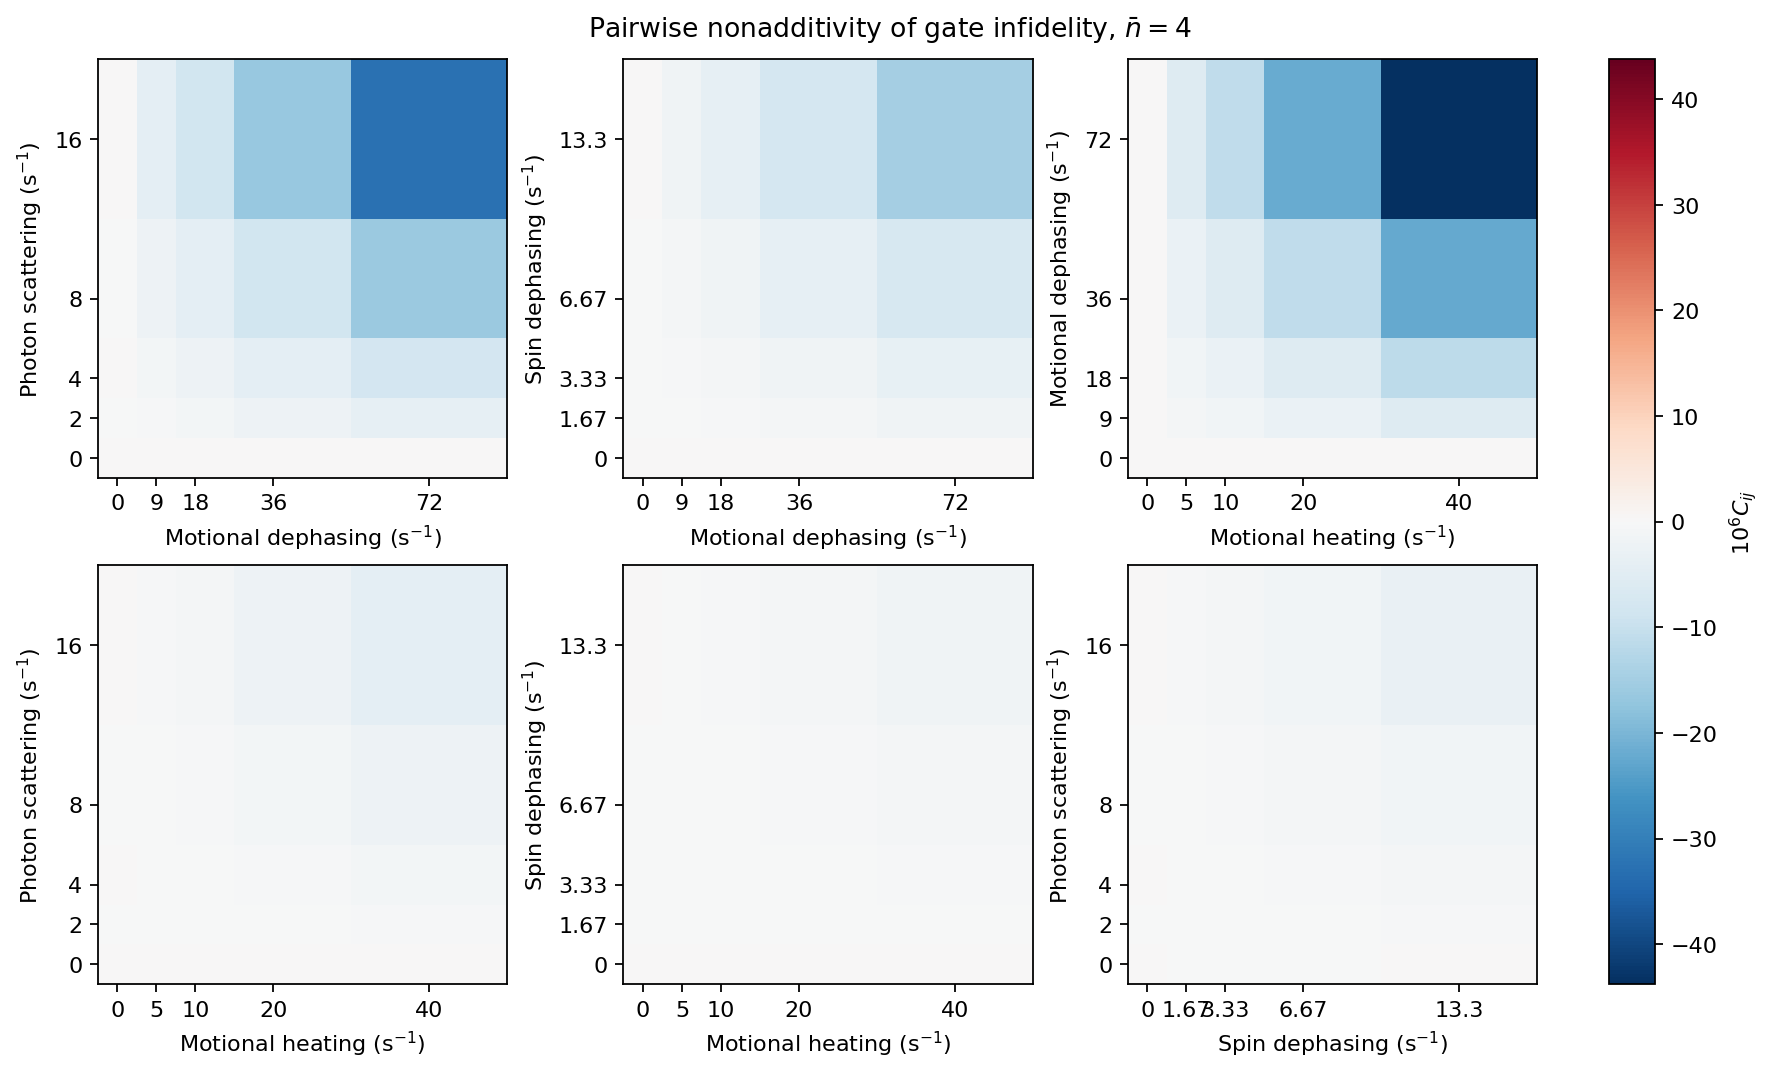

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

NBAR_PAIR = 4.0
folder = Path("results/noise_rate_nbar_sweep/all_pairwise_5x5_grids")
data = pd.read_csv(folder / "all_pairwise_grid_interactions.csv")
subset = data[data.nbar == NBAR_PAIR]
if subset.empty:
    raise ValueError(f"Available occupations: {sorted(data.nbar.unique())}")
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6), layout="constrained")
limit = subset.interaction_infidelity.abs().max() * 1e6
for ax, (_, pair) in zip(axes.flat, subset.groupby("pair_id")):
    grid = pair.pivot(index="strength_y_s^-1", columns="strength_x_s^-1",
                      values="interaction_infidelity").sort_index().sort_index(axis=1)
    im = ax.pcolormesh(grid.columns, grid.index, grid.values * 1e6,
                       shading="nearest", cmap="RdBu_r", vmin=-limit, vmax=limit)
    for axis, key, ticks in [(ax.xaxis, "source_x", grid.columns), (ax.yaxis, "source_y", grid.index)]:
        axis.set_ticks(ticks)
        axis.set_ticklabels([f"{v:.3g}" for v in ticks])
        axis.set_label_text(pair[key].iloc[0].replace("_", " ").capitalize() + r" ($\mathrm{s}^{-1}$)")
fig.suptitle(rf"Pairwise nonadditivity of gate infidelity, $\bar n={NBAR_PAIR:g}$")
fig.colorbar(im, ax=axes, label=r"$10^6 C_{ij}$")
target = Path("figures") / f"pairwise_infidelity_nbar_{NBAR_PAIR:g}"
target.parent.mkdir(exist_ok=True)
for ext in [".pdf", ".png"]:
    fig.savefig(Path(str(target) + ext), dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(target)+".png"))


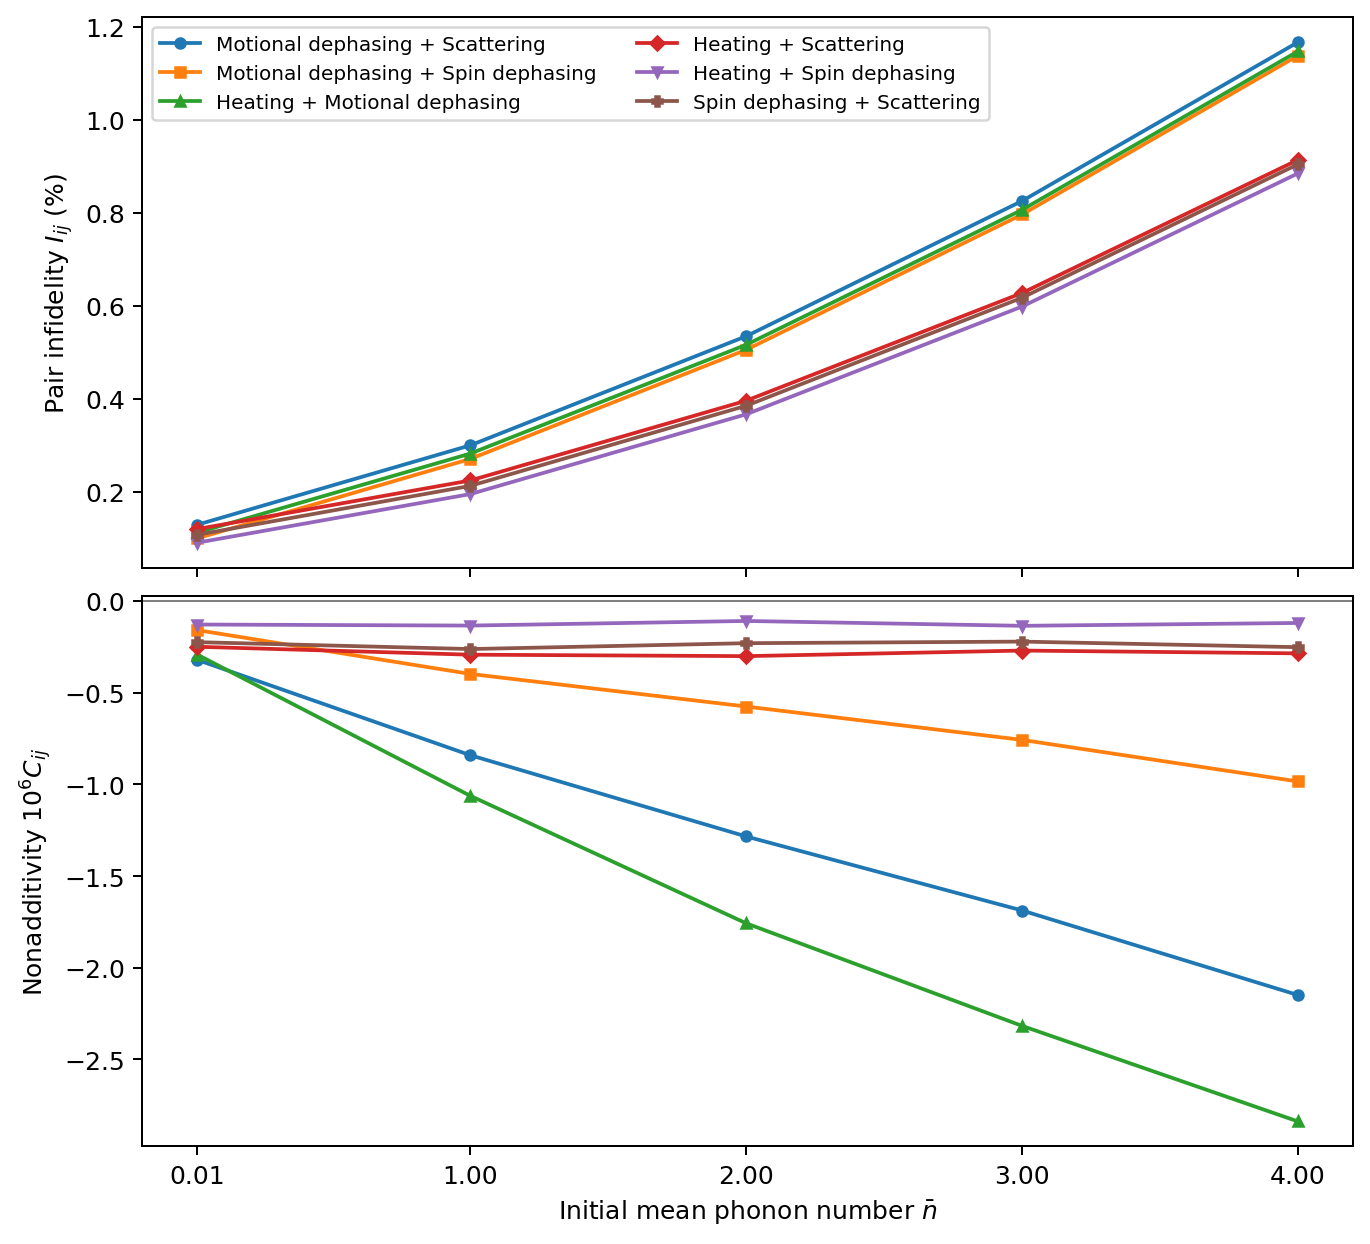

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

grid = pd.read_csv("results/noise_rate_nbar_sweep/all_pairwise_5x5_grids/all_pairwise_grid_interactions.csv")
nominal = grid.query("multiplier_x == 1 and multiplier_y == 1")
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(7.5, 6.8), layout="constrained")
names = {"motional_heating": "Heating", "motional_dephasing": "Motional dephasing",
         "spin_dephasing": "Spin dephasing", "photon_scattering": "Scattering"}
for (_, pair), marker in zip(nominal.groupby("pair_id"), "os^DvP"):
    pair = pair.sort_values("nbar")
    x = pair.nbar
    label = names[pair.source_x.iloc[0]] + " + " + names[pair.source_y.iloc[0]]
    top.plot(x, 100 * pair.grid_infidelity, marker=marker, label=label, ms=4)
    c = pair.grid_infidelity - pair.x_only_infidelity - pair.y_only_infidelity + pair.zero_infidelity
    np.testing.assert_allclose(c, pair.interaction_infidelity, atol=1e-14)
    bottom.plot(x, 1e6 * c, marker=marker, ms=4)
top.set_ylabel(r"Pair infidelity $I_{ij}$ (%)")
bottom.set_ylabel(r"Nonadditivity $10^6 C_{ij}$")
bottom.set_xlabel(r"Initial mean phonon number $\bar n$")
bottom.set_xticks(sorted(nominal.nbar.unique()))
bottom.axhline(0, color="0.5", lw=0.8)
top.legend(ncol=2, fontsize=8)
out = Path("figures/pair_infidelity_and_nonadditivity")
out.parent.mkdir(exist_ok=True)
for suffix in (".pdf", ".png"):
    fig.savefig(out.with_suffix(suffix), dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(out.with_suffix(".png"))))


## ノイズ源の組み合わせ別の平均ゲート infidelity
各ノイズ源は ON のとき公称レート、OFF のときゼロとする。縦軸は校正前の平均ゲート infidelity $100(1-F_{\rm avg})$（%）。3枚とも同じ軸範囲で比較する。

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

figure_dir = Path("figures")
all_rates = pd.read_csv("results/noise_rate_nbar_sweep/sensitivity_vs_nominal.csv")
full_channel = all_rates.query("multiplier == 1 and noise_source == 'motional_heating'").set_index("nbar").sort_index()
pair_grid = pd.read_csv("results/noise_rate_nbar_sweep/all_pairwise_5x5_grids/all_pairwise_grid_interactions.csv")
nominal_pairs = pair_grid.query("multiplier_x == 1 and multiplier_y == 1")
source_labels = {"motional_heating": "Heating", "motional_dephasing": "Motional dephasing",
                 "spin_dephasing": "Spin dephasing", "photon_scattering": "Scattering"}
single_curves = {}
pair_curves = {}
for (left, right), rows in nominal_pairs.groupby(["source_x", "source_y"]):
    rows = rows.set_index("nbar").sort_index()
    for source_name, column in [(left, "x_only_infidelity"), (right, "y_only_infidelity")]:
        single_curves[source_labels[source_name]] = rows[column]
    pair_curves[f"{source_labels[left]} + {source_labels[right]}"] = rows["grid_infidelity"]

all_curves = {"All four sources": full_channel["infidelity"]}
upper_percent = 105 * max(s.max() for curves in (all_curves, single_curves, pair_curves) for s in curves.values())

def save_result_figure(fig, stem):
    figure_dir.mkdir(exist_ok=True)
    for extension in ("pdf", "png"):
        fig.savefig(figure_dir / f"{stem}.{extension}", dpi=180, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(figure_dir / f"{stem}.png")))

def plot_infidelity(curves, title, stem):
    fig, ax = plt.subplots(figsize=(7, 4.8), constrained_layout=True)
    for (label, series), marker in zip(curves.items(), "os^DvP"):
        ax.plot(series.index, 100 * series, marker=marker, ms=5, label=label)
    ax.set(title=title, xlabel=r"Initial mean phonon number $\bar n$", ylabel=r"Average gate infidelity $1-F_{\rm avg}$ (%)",
           ylim=(0, upper_percent), xticks=full_channel.index)
    if len(curves) > 1:
        ax.legend(fontsize=8)
    save_result_figure(fig, stem)

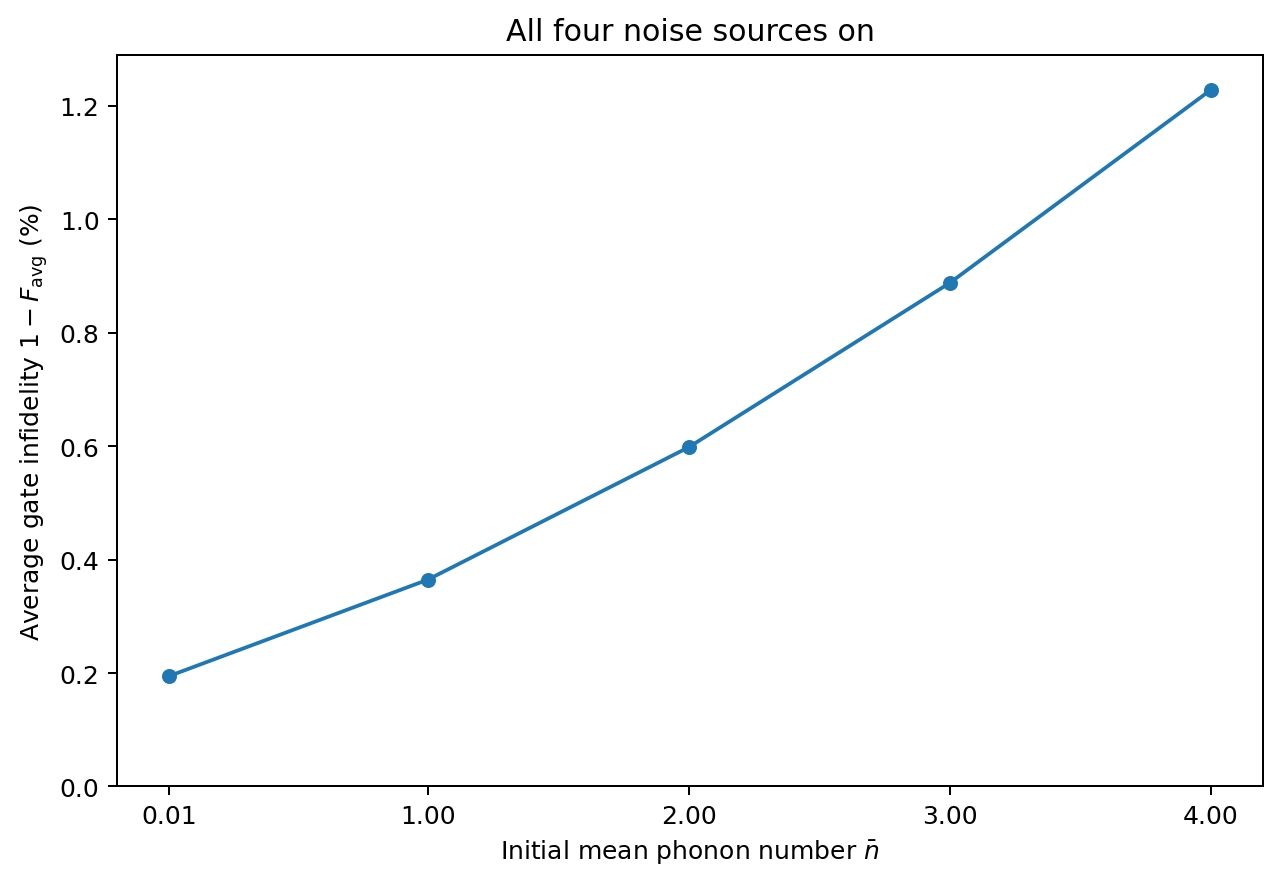

In [ ]:
plot_infidelity(all_curves, "All four noise sources on", "infidelity_all_nominal")

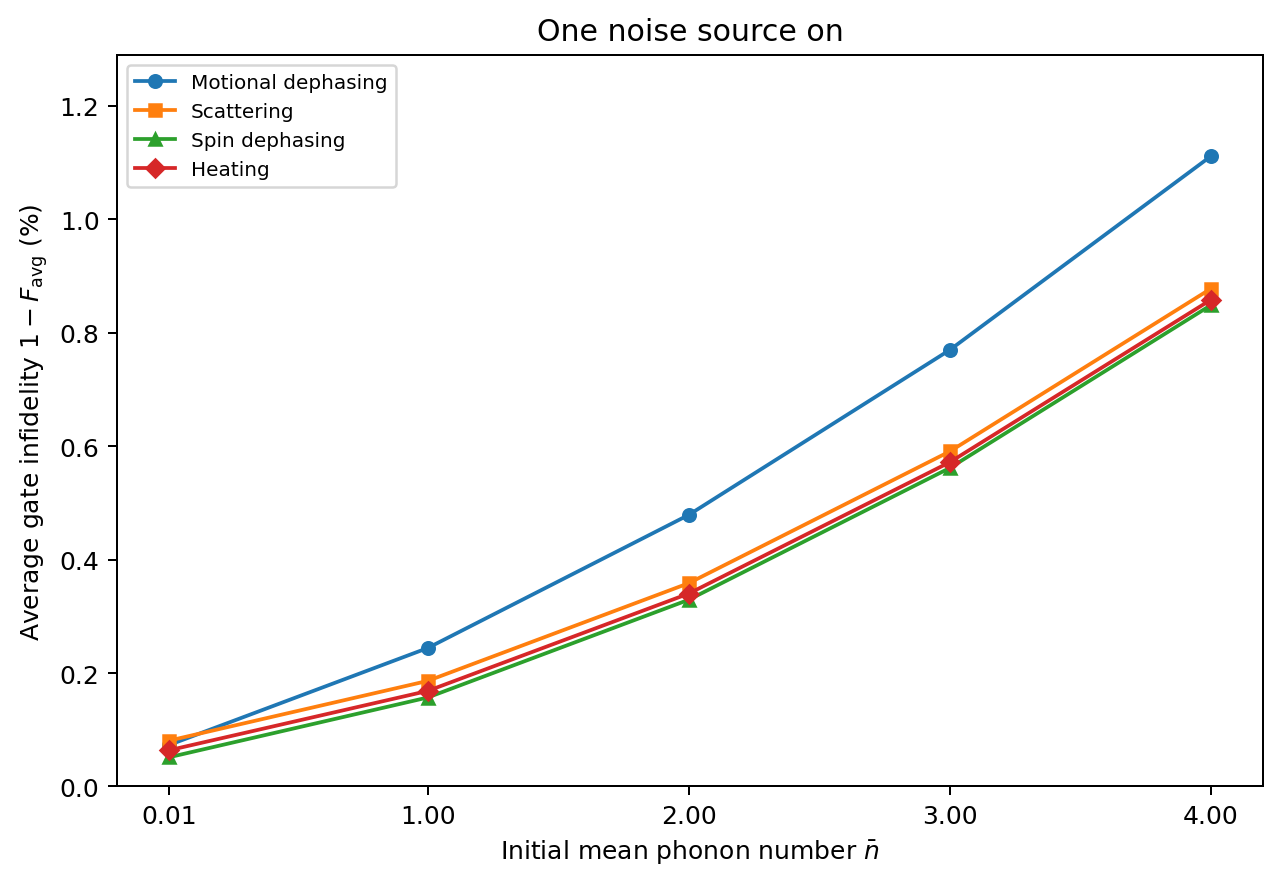

In [ ]:
plot_infidelity(single_curves, "One noise source on", "infidelity_single_nominal")

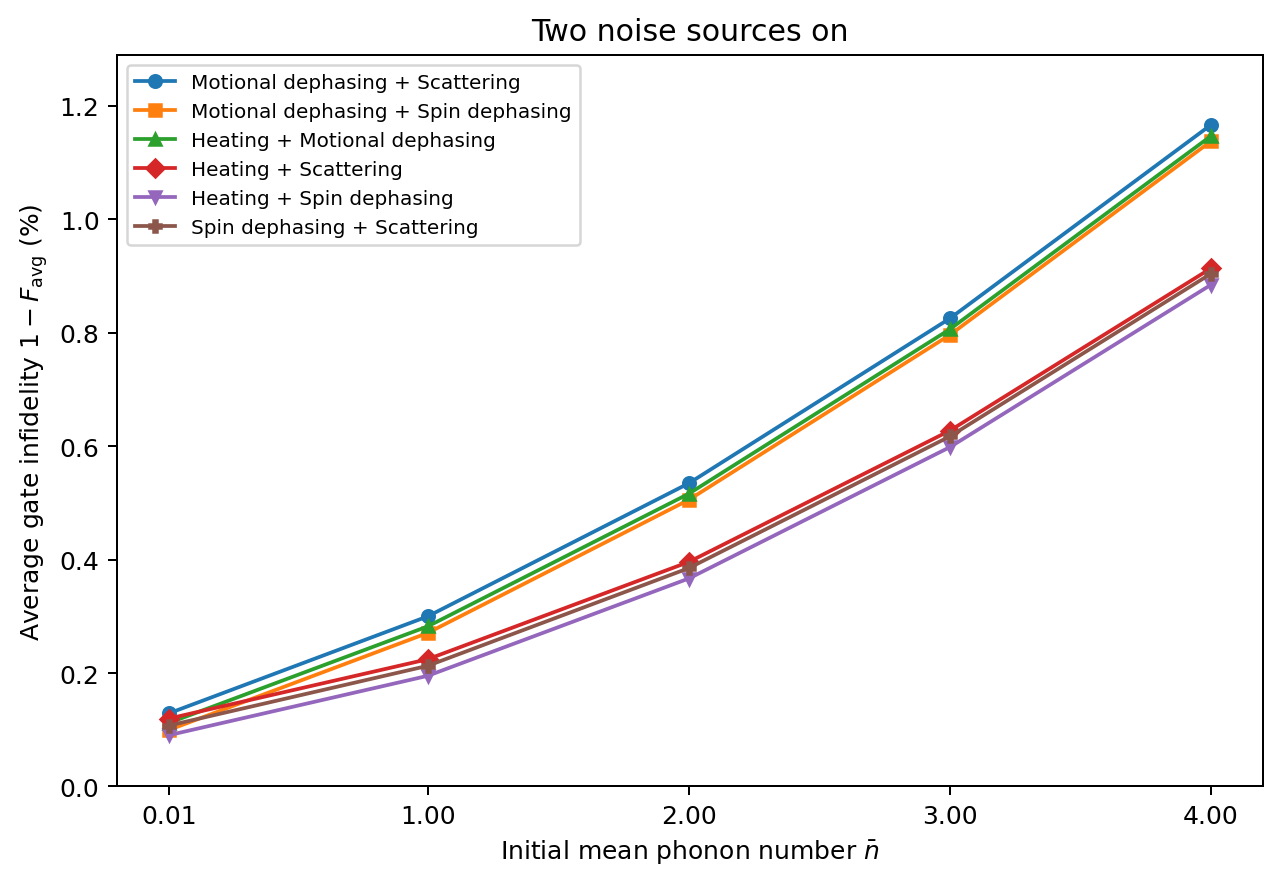

In [ ]:
plot_infidelity(pair_curves, "Two noise sources on", "infidelity_pair_nominal")

## (b) 全ノイズ ON の符号付き誤差生成子係数
全4源が公称レートの保存済みチャネルを CPTP 射影し、Pauli transfer matrix の対数を完全な H/S/C/A 基底で分解する。$\bar n=2,3,4$ の各点で絶対値が上位5位に入る係数を、公称レートでの全計算点について符号付きで示す。

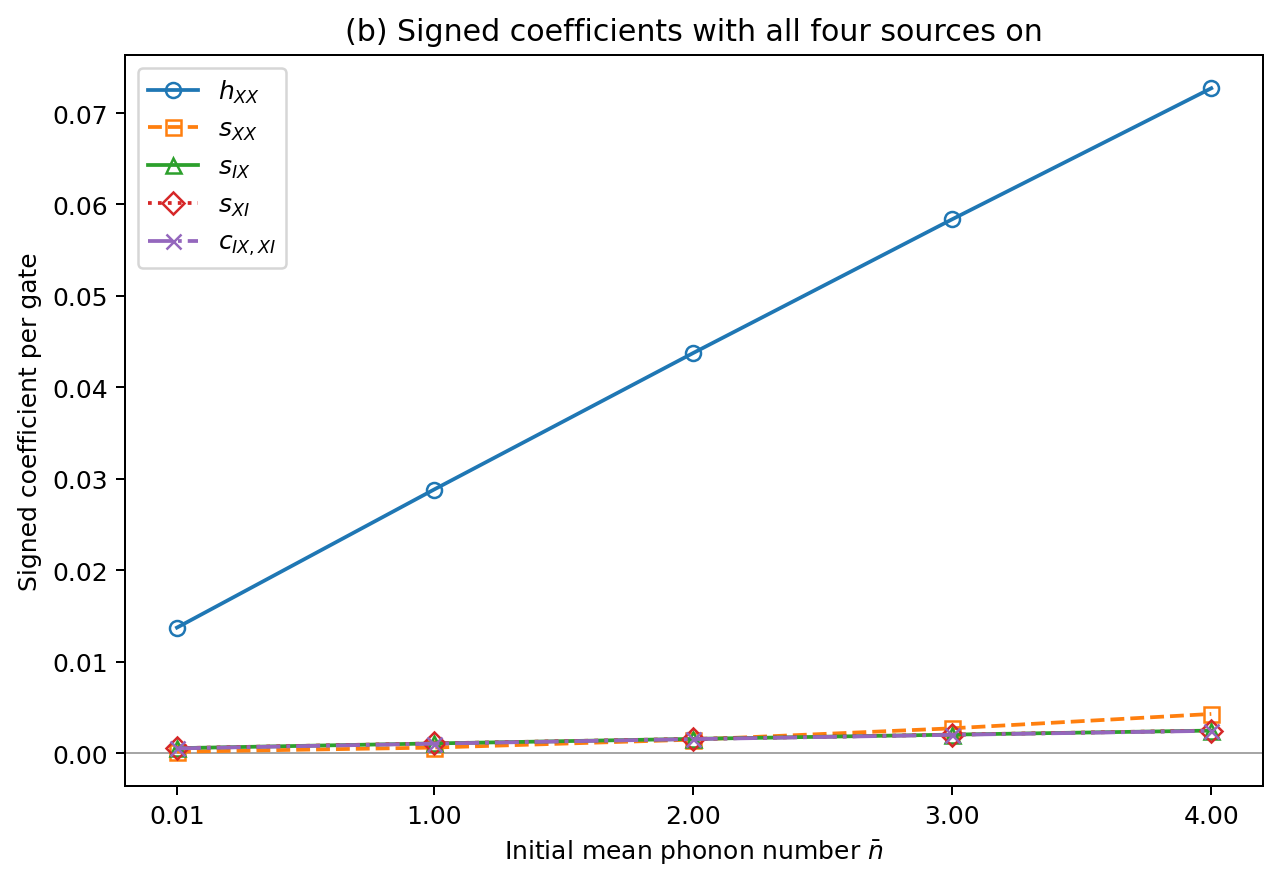

In [ ]:
import numpy as np
from scipy.linalg import logm
from drive_calibration_qpt_analysis import project_trace_normalized_chi_to_cptp
from ms_gate_functions import superoperator_to_ptm
from noise_error_structure import _decompose_generator_taxonomy

generator_dir = Path("results/error_generator_rate_nbar")
requests = pd.read_csv(generator_dir / "sweep_requests.csv")
nominal_id, = requests.query("multiplier == 1").condition_id.unique()
index = pd.read_csv(generator_dir / "channel_cache_index.csv")
coefficients = {}
for point in index[index.condition_id == nominal_id].itertuples():
    with np.load(point.cache_path) as data:
        channel, _, _ = project_trace_normalized_chi_to_cptp(data["chi_trace_normalized"])
    fit = _decompose_generator_taxonomy(logm(superoperator_to_ptm(channel)).real)
    coefficients[point.nbar] = {f"{sector}:{mode}": v for (sector, mode), v
                                in zip(fit["metadata"], fit["coefficients"])}
nominal_sweep = pd.DataFrame(coefficients).sort_index(axis=1)
signed_terms = ["H:XX", "S:XX", "S:IX", "S:XI", "C:IX,XI"]
for nbar in (2, 3, 4):
    if set(nominal_sweep[nbar].abs().nlargest(5).index) != set(signed_terms):
        raise ValueError(f"Top five coefficients differ at nbar={nbar}")

fig, ax = plt.subplots(figsize=(7, 4.8), constrained_layout=True)
ax.axhline(0, color="0.65", lw=0.8)
for term, marker, style in zip(signed_terms, "os^Dx", ["-", "--", "-", ":", "-."]):
    sector, mode = term.split(":")
    ax.plot(nominal_sweep.columns, nominal_sweep.loc[term], marker=marker, ls=style, fillstyle="none",
            label=rf"${sector.lower()}_{{{mode}}}$")
ax.set(title="(b) Signed coefficients with all four sources on",
       xlabel=r"Initial mean phonon number $\bar n$", ylabel="Signed coefficient per gate",
       xticks=nominal_sweep.columns)
ax.legend()
save_result_figure(fig, "signed_coefficients_all_nominal")

## 矩形パルスの駆動振幅較正と残留誤差

全4ノイズ源を公称レートに固定し、各 $\bar n$ で公称振幅 $A_0=0.125$ と、$h_{XX}$ をゼロに近づけるよう調整した振幅 $A_\ast(\bar n)$ を比較する。表1は振幅比、$h_{XX}$（rad/gate）、平均ゲート不忠実度 $100(1-F_{\rm avg})$（%）を示す。

表2・3は CPTP 射影後の誤差チャネルの PTM 対数を共通の H/S/C/A 基底に分解した結果である。各欄に係数名と1ゲート当たりの符号付き値を記す。表2は較正による変化 $\Delta c_k=c_k(A_\ast)-c_k(A_0)$、表3は較正後の値 $c_k(A_\ast)$ を、それぞれ絶対値の降順に並べた。

In [14]:
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display

drive_dir = Path("results/calibration_channel_comparison")
drive_pairs = pd.read_csv(drive_dir / "channel_comparison_paired.csv").set_index("n_bar")
drive_top = pd.read_csv(drive_dir / "drive_calibration_hsca_top5.csv")
drive_summary = pd.DataFrame({
    "A*/A₀": drive_pairs["A_factor_after"],
    "h_XX 較正前": drive_pairs["h_XX_rad_per_gate_before"],
    "h_XX 較正後": drive_pairs["h_XX_rad_per_gate_after"],
    "不忠実度 較正前 (%)": 100 * drive_pairs["average_infidelity_before"],
    "不忠実度 較正後 (%)": 100 * drive_pairs["average_infidelity_after"],
})
drive_summary.index.name = "平均フォノン数"
display(Markdown("**表1　各温度での振幅較正**"))
display(drive_summary.round(6))

for ranking, title in [
    ("change", "表2　較正で変化した上位5成分（符号付き変化量）"),
    ("residual", "表3　較正後の上位5成分（符号付き係数）"),
]:
    subset = drive_top.loc[drive_top["ranking"] == ranking].copy()
    subset["成分と値"] = (subset["sector"] + ":" + subset["pauli"] + "  "
                        + subset["signed_value"].map("{:+.5e}".format))
    ranked = subset.pivot(index="n_bar", columns="rank", values="成分と値")
    ranked.index.name = "平均フォノン数"
    ranked.columns = [f"{rank}位" for rank in ranked.columns]
    display(Markdown(f"**{title}**"))
    display(ranked)

**表1　各温度での振幅較正**

,A*/A₀,h_XX 較正前,h_XX 較正後,不忠実度 較正前 (%),不忠実度 較正後 (%)
平均フォノン数,,,,,
0.01,1.008861,0.013736,0.000102,0.194653,0.181869
1.00,1.018859,0.028806,0.000212,0.364438,0.310427
2.00,1.029065,0.043740,0.000312,0.598075,0.479633
4.00,1.049773,0.072711,0.000434,1.228080,0.936560
6.00,1.070830,0.100464,0.000363,2.037337,1.551204
8.00,1.092215,0.127023,-0.000028,2.982973,2.318937
10.00,1.113932,0.152443,-0.000873,4.028153,3.233552


**表2　較正で変化した上位5成分（符号付き変化量）**

,1位,2位,3位,4位,5位
平均フォノン数,,,,,
0.01,H:XX -1.36340e-02,S:XI +1.13599e-05,"C:IX,XI +1.13580e-05",S:IX +1.13561e-05,S:XX +5.80110e-06
1.00,H:XX -2.85939e-02,S:XI +5.23282e-05,"C:IX,XI +5.23252e-05",S:IX +5.23226e-05,S:XX +4.70734e-05
2.00,H:XX -4.34276e-02,S:XX +1.77001e-04,S:IX +1.22366e-04,"C:IX,XI +1.22359e-04",S:XI +1.22353e-04
4.00,H:XX -7.22765e-02,S:XX +8.97465e-04,S:IX +3.43372e-04,"C:IX,XI +3.43357e-04",S:XI +3.43343e-04
6.00,H:XX -1.00101e-01,S:XX +2.52018e-03,S:XI +6.63834e-04,"C:IX,XI +6.63827e-04",S:IX +6.63805e-04
8.00,H:XX -1.27051e-01,S:XX +5.34119e-03,"C:IX,XI +1.07560e-03",S:IX +1.07559e-03,S:XI +1.07559e-03
10.00,H:XX -1.53316e-01,S:XX +9.61637e-03,S:XI +1.57187e-03,"C:IX,XI +1.57184e-03",S:IX +1.57183e-03


**表3　較正後の上位5成分（符号付き係数）**

,1位,2位,3位,4位,5位
平均フォノン数,,,,,
0.01,S:XI +5.61973e-04,S:IX +5.61964e-04,"C:IX,XI +5.36981e-04",S:IZ +1.74028e-04,S:ZI +1.74028e-04
1.00,S:XI +1.12276e-03,S:IX +1.12275e-03,"C:IX,XI +1.09776e-03",S:XX +6.62958e-04,H:XX +2.12392e-04
2.00,S:IX +1.68909e-03,S:XI +1.68908e-03,"C:IX,XI +1.66409e-03",S:XX +1.66171e-03,H:XX +3.12228e-04
4.00,S:XX +5.19058e-03,S:IX +2.81956e-03,S:XI +2.81955e-03,"C:IX,XI +2.79456e-03",H:XX +4.34290e-04
6.00,S:XX +1.07943e-02,S:XI +3.95390e-03,S:IX +3.95387e-03,"C:IX,XI +3.92890e-03",H:XX +3.63092e-04
8.00,S:XX +1.84944e-02,S:IX +5.09337e-03,S:XI +5.09334e-03,"C:IX,XI +5.06836e-03",S:IZ +1.33805e-04
10.00,S:XX +2.83147e-02,S:XI +6.23979e-03,S:IX +6.23972e-03,"C:IX,XI +6.21476e-03",H:XX -8.72615e-04


$\bar n=4$ では振幅比 $A_\ast/A_0=1.04977$ で $h_{XX}$ が $0.07271$ から $0.000434$ rad/gate に下がり、平均不忠実度は $1.228\%$ から $0.937\%$ に下がった。一方、$S_{XX}$ は $8.97\times10^{-4}$ 増え、較正後の最大成分（$5.19\times10^{-3}$）になった。この温度の変化量3〜5位はほぼ同じ大きさで、収束チェックは追加精査を要するため、これらの順位差の解釈は保留する。

**振幅ずれへの感度（未集計）**　公称振幅に対する $A/A_0=0.99,\ 1.01$ の変化量上位5成分は未確認である。表2の振幅比は各温度の角度較正で決まる。

### 駆動振幅較正の温度依存性

図1は矩形パルスの較正振幅比、較正前後の $h_{XX}$ と平均ゲート不忠実度を示す。中央の縦軸はゼロ付近が線形の対称対数目盛である。

図2の上段は公称振幅からの係数変化、下段は較正後の係数である。各マスに絶対値の順位と符号付きの値を示す。色は両段共通の対称対数目盛で、灰色はその温度で上位5成分の圏外を表す。

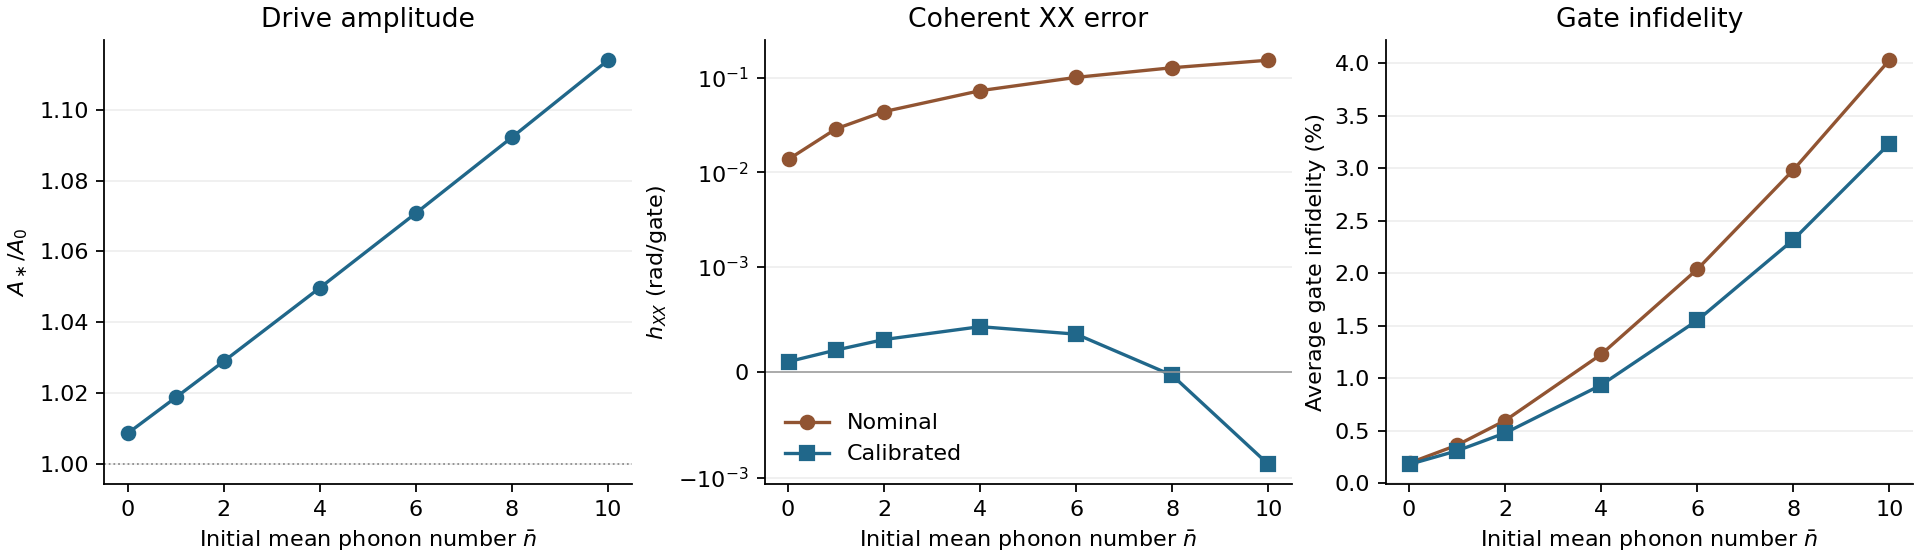

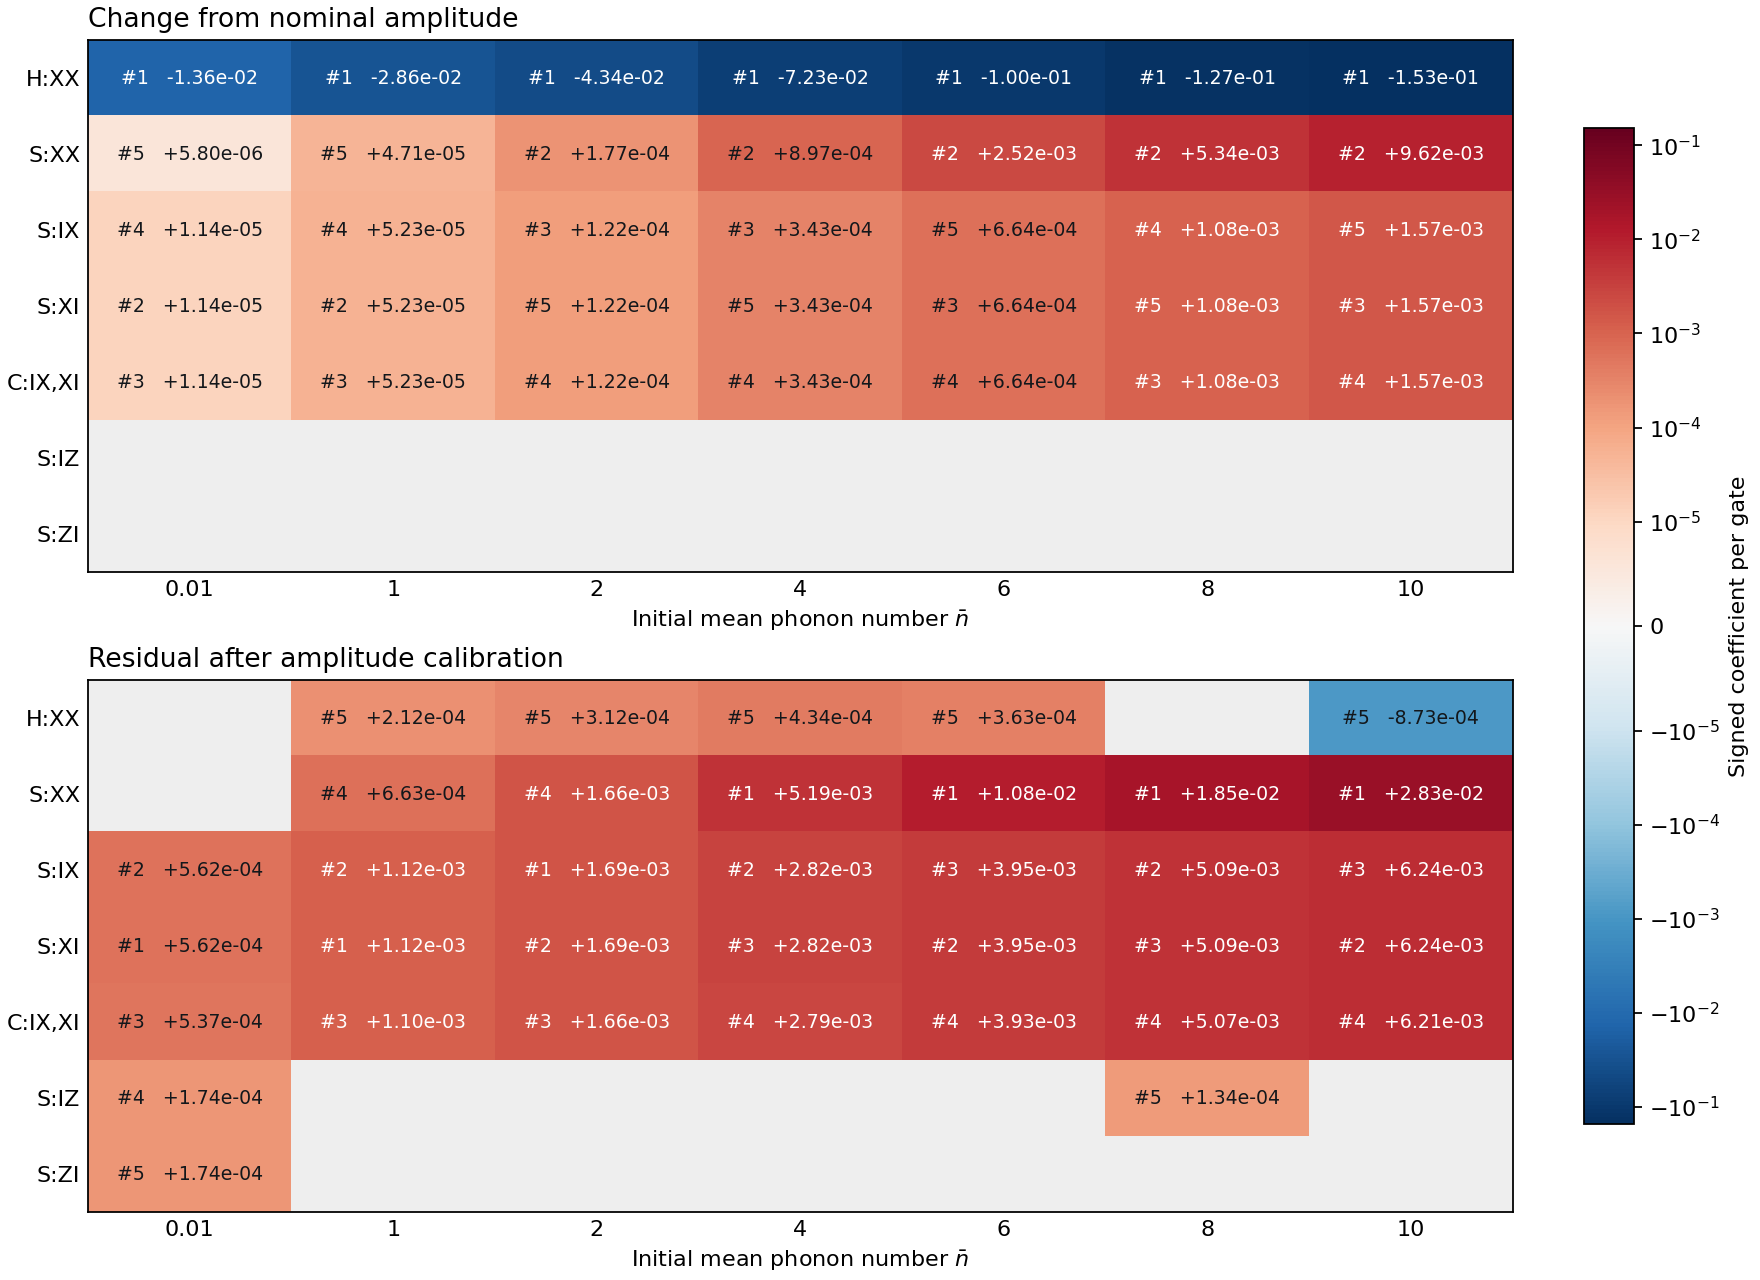

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from pathlib import Path
from IPython.display import Image, display

drive_dir = Path("results/calibration_channel_comparison")
pairs = pd.read_csv(drive_dir / "channel_comparison_paired.csv").sort_values("n_bar")
top = pd.read_csv(drive_dir / "drive_calibration_hsca_top5.csv")
nbar = pairs["n_bar"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
axes[0].plot(nbar, pairs["A_factor_after"], "o-", color="#20678a")
axes[0].axhline(1, color="0.55", lw=0.8, ls=":")
axes[0].set_ylabel(r"$A_\ast/A_0$")
for stage, label, color, marker in [("before", "Nominal", "#915432", "o"),
                                    ("after", "Calibrated", "#20678a", "s")]:
    axes[1].plot(nbar, pairs[f"h_XX_rad_per_gate_{stage}"], marker=marker, color=color, label=label)
    axes[2].plot(nbar, 100*pairs[f"average_infidelity_{stage}"], marker=marker, color=color)
axes[1].set_yscale("symlog", linthresh=0.001)
axes[1].axhline(0, color="0.6", lw=0.7)
axes[1].set_ylabel(r"$h_{XX}$ (rad/gate)")
axes[2].set_ylabel("Average gate infidelity (%)")
axes[1].legend(frameon=False)
for ax, title in zip(axes, ["Drive amplitude", "Coherent XX error", "Gate infidelity"]):
    ax.set_title(title)
    ax.set_xlabel(r"Initial mean phonon number $\bar n$")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
path = drive_dir / "drive_calibration_vs_nbar.png"
fig.savefig(path, dpi=160)
plt.close(fig)
display(Image(filename=str(path), width=1060))

top["term"] = top["sector"] + ":" + top["pauli"]
terms = ["H:XX", "S:XX", "S:IX", "S:XI", "C:IX,XI", "S:IZ", "S:ZI"]
fig, axes = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)
limit = top["signed_value"].abs().max()
norm = SymLogNorm(linthresh=1e-5, vmin=-limit, vmax=limit)
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#eeeeee")
for ax, key, title in zip(axes, ["change", "residual"],
                          ["Change from nominal amplitude", "Residual after amplitude calibration"]):
    data = top[top["ranking"] == key]
    values = data.pivot(index="term", columns="n_bar", values="signed_value").reindex(index=terms, columns=nbar)
    ranks = data.pivot(index="term", columns="n_bar", values="rank").reindex_like(values)
    im = ax.imshow(values, cmap=cmap, norm=norm, aspect="auto")
    for i, j in zip(*np.where(values.notna())):
        v = values.iloc[i,j]
        ink = "white" if norm(v) < 0.21 or norm(v) > 0.79 else "#13171b"
        ax.text(j, i, f"#{int(ranks.iloc[i,j])}   {v:+.2e}", ha="center", va="center", fontsize=8.5, color=ink)
    ax.set_xticks(range(len(nbar)), [f"{x:g}" for x in nbar])
    ax.set_yticks(range(len(terms)), terms)
    ax.set_title(title, loc="left")
    ax.set_xlabel(r"Initial mean phonon number $\bar n$")
    ax.tick_params(length=0)
fig.colorbar(im, ax=axes, shrink=0.85, label="Signed coefficient per gate")
path = drive_dir / "drive_calibration_hsca_top5.png"
fig.savefig(path, dpi=160)
plt.close(fig)
display(Image(filename=str(path), width=1030))


## パルス整形後の誤差生成子：等時間・角度較正後の比較

$\bar n=4$、両波形のゲート時間を $T=225.8\,\mu\mathrm{s}$ に固定し、1ループの矩形を基準に振幅・離調ランプを比較する。矩形の離調は $\delta/(2\pi)=1/T$、公称結合は $A_0/(2\pi)=1/(4T)$。ランプは振幅の立上り・立下りが各5 µs、離調掃引が各100 µs、保持時間が15.8 µsで、離調範囲は22.245–400 kHzとした。波形ごとに振幅全体に一つの係数を掛け、目標 $\exp(+i\pi XX/4)$ に対して $|h_{XX}|\le 2\times 10^{-3}$ rad/gate を満たすことをQPTで確認した。表の振幅比の分母は各波形の公称ピーク振幅である。[ランプ方式を参考にした Bowers らの論文](https://arxiv.org/pdf/2511.14364)

加熱 10 s⁻¹、運動位相緩和 18 s⁻¹、$T_2^*=0.3$ s、Rayleigh 3 s⁻¹、Raman 1 s⁻¹。散乱率は駆動強度によらず一定とした。両波形とも $\eta=0.1$、既存の有限次数補正、フォノン次元67、時間格子1501点、最大時間刻み0.05 µsを使用した。

左図は $|c_k^{\rm ramp}-c_k^{\rm rect}|$ の上位5成分を選び、両波形の符号付き係数を並べたもの。右図はランプ較正後の $|c_k^{\rm ramp}|$ の上位5成分。表には比較に用いた符号付き差も示す。

,T (µs),A*/A₀,Peak A*/2π (kHz),h_XX (rad/gate),Infidelity (%)
Pulse,,,,,
Rectangular,225.8,1.049773,1.162282,0.000069,1.482740
Ramp,225.8,1.046687,3.140061,-0.000038,0.660418


**波形変更で動いた上位5成分（1ゲート当たり）**

,Rectangular,Ramp,Ramp − Rectangular
"C:IX,XI",+5.53375e-03,+4.33381e-04,-5.10037e-03
S:XI,+5.59017e-03,+4.89807e-04,-5.10036e-03
S:IX,+5.59017e-03,+4.89810e-04,-5.10036e-03
S:XX,+5.41478e-03,+5.10360e-03,-3.11184e-04
H:XX,+6.86502e-05,-3.80621e-05,-1.06712e-04


**ランプ較正後の上位5成分（1ゲート当たり）**

,Ramp
S:XX,+5.10360e-03
S:IX,+4.89810e-04
S:XI,+4.89807e-04
"C:IX,XI",+4.33381e-04
S:IZ,+4.07440e-04


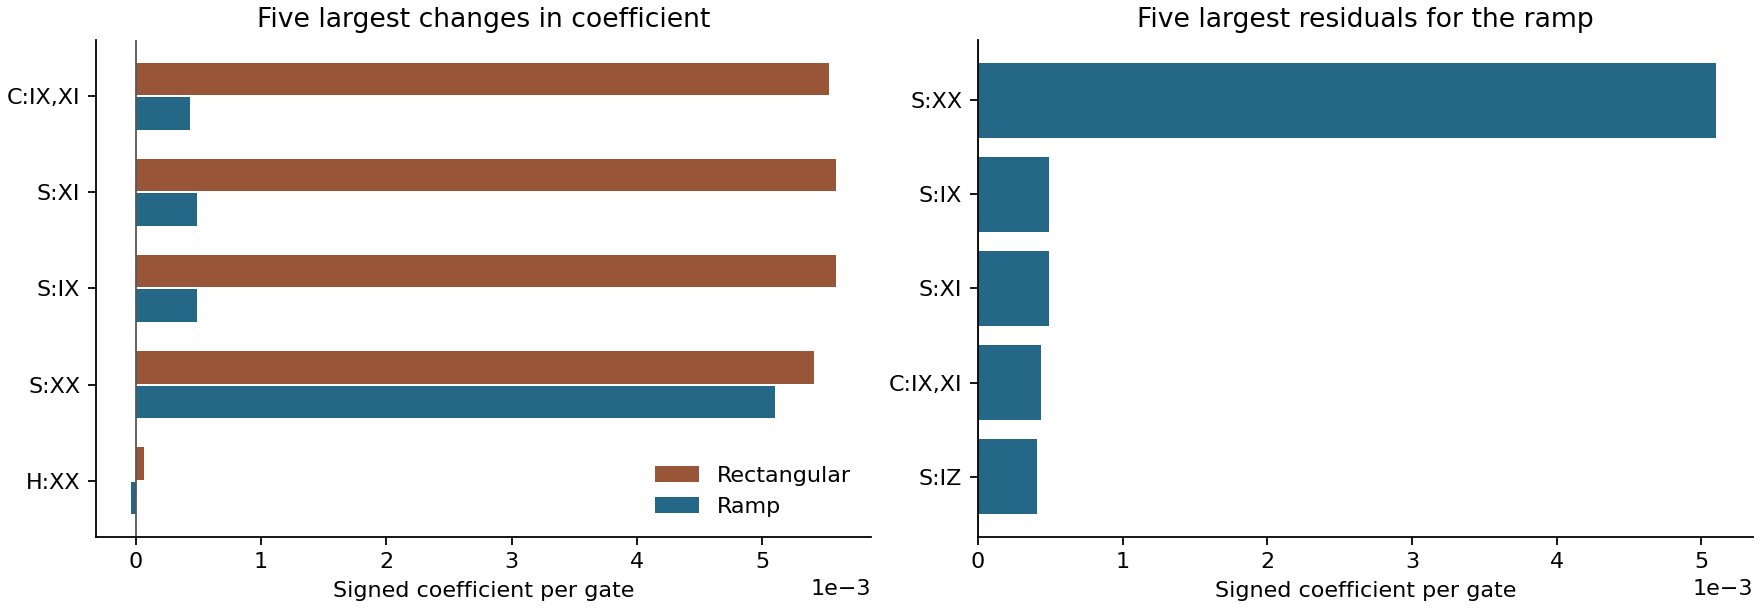

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from scipy.linalg import logm
import noise_error_structure as ns
from drive_calibration_qpt_analysis import project_trace_normalized_chi_to_cptp

pulse_dir = Path("results/matched_pulse_calibration_nbar4")
pulse_coeffs = {}
pulse_metrics = []
for key, name in [("standard", "Rectangular"), ("smooth_detuning", "Ramp")]:
    with np.load(pulse_dir / f"{key}.npz") as data:
        channel, chi, _ = project_trace_normalized_chi_to_cptp(data["chi"])
        generator = logm(ns.mg.superoperator_to_ptm(channel))
        assert np.linalg.norm(generator.imag) < 1e-8
        terms = ns._decompose_generator_taxonomy(generator.real)
        labels = [f"{sector}:{mode}" for sector, mode in terms["metadata"]]
        values = pd.Series(terms["coefficients"], index=labels)
        assert len(values) == 240 and abs(values["H:XX"]) <= 2e-3
        pulse_coeffs[name] = values
        pulse_metrics.append([name, data["gate_time_s"].item()*1e6,
                              data["scale"].item(), data["peak_hz"].item()/1e3,
                              values["H:XX"], 80*(1-chi[0,0].real)])
metrics = pd.DataFrame(pulse_metrics, columns=["Pulse", "T (µs)", "A*/A₀",
                       "Peak A*/2π (kHz)", "h_XX (rad/gate)", "Infidelity (%)"])
display(metrics.set_index("Pulse").round(6))

coeff = pd.DataFrame(pulse_coeffs)
coeff["Ramp − Rectangular"] = coeff["Ramp"] - coeff["Rectangular"]
diff = coeff.loc[coeff["Ramp − Rectangular"].abs().nlargest(5).index]
res = coeff["Ramp"].loc[coeff["Ramp"].abs().nlargest(5).index]
display(Markdown("**波形変更で動いた上位5成分（1ゲート当たり）**"))
display(diff.style.format("{:+.5e}"))
display(Markdown("**ランプ較正後の上位5成分（1ゲート当たり）**"))
display(res.to_frame().style.format("{:+.5e}"))

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
y = np.arange(len(diff))
ax.barh(y-0.18, diff["Rectangular"], 0.34, color="#985537", label="Rectangular")
ax.barh(y+0.18, diff["Ramp"], 0.34, color="#246787", label="Ramp")
ax.set_yticks(y, diff.index)
ax.set_title("Five largest changes in coefficient")
ax.legend(frameon=False)
bx.barh(np.arange(len(res)), res, color="#246787")
bx.set_yticks(np.arange(len(res)), res.index)
bx.set_title("Five largest residuals for the ramp")
for panel in (ax, bx):
    panel.invert_yaxis()
    panel.axvline(0, lw=0.8, color="#555555")
    panel.set_xlabel("Signed coefficient per gate")
    panel.ticklabel_format(axis="x", style="sci", scilimits=(-2,2))
    panel.spines[["right","top"]].set_visible(False)
figure_path = pulse_dir / "calibrated_pulse_comparison.png"
fig.savefig(figure_path, dpi=160)
plt.close(fig)
display(Image(filename=str(figure_path), width=1040))


この条件の平均ゲート不忠実度は矩形 1.4827%、ランプ 0.6604% であった。絶対変化が最大の成分は **C:IX,XI**（ランプ − 矩形 -5.100e-03/gate）。矩形の $S_{XX}$ は +5.415e-03、ランプでは +5.104e-03 で、ランプの最大残留成分は **S:XX**（+5.104e-03/gate）となった。値は上記の数値設定での結果であり、この波形対について打ち切り次元・刻みを変えた収束検証は未実施である。

### 公称矩形・振幅較正済み矩形・振幅較正済みランプの平均ゲート不忠実度

3条件とも初期平均フォノン数は4、ゲート時間は225.8 µs。上から順に、公称振幅の矩形、同じ矩形の振幅較正後、振幅・離調ランプの振幅較正後を示す。散逸率は前図と同一で、光散乱率は駆動強度によらず一定とした。

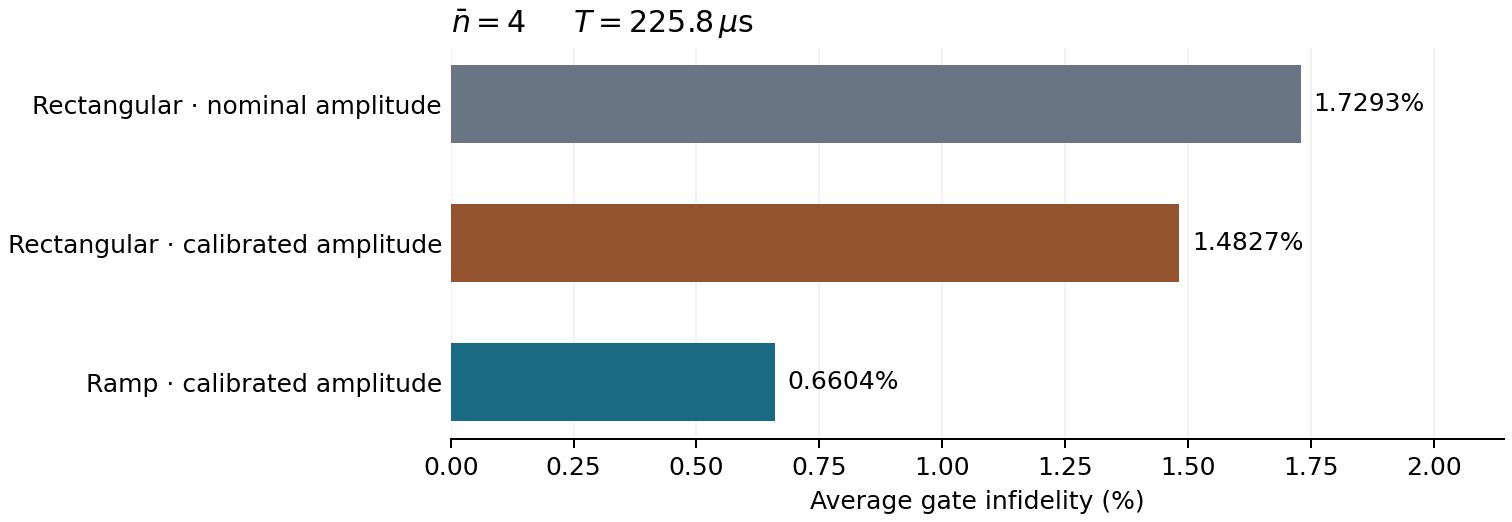

In [17]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from drive_calibration_qpt_analysis import extract_xx_generator_observables

pulse_dir = Path("results/matched_pulse_calibration_nbar4")
conditions = [
    ("standard_nominal", "Rectangular · nominal amplitude"),
    ("standard", "Rectangular · calibrated amplitude"),
    ("smooth_detuning", "Ramp · calibrated amplitude"),
]
percent = []
for key, label in conditions:
    with np.load(pulse_dir / f"{key}.npz") as data:
        assert np.isclose(data["gate_time_s"], 225.8e-6, rtol=0, atol=1e-12)
        obs = extract_xx_generator_observables(data["chi"])
        percent.append(100 * obs["average_infidelity"])

fig, ax = plt.subplots(figsize=(8.4, 2.9), constrained_layout=True)
bars = ax.barh([label for _, label in conditions], percent,
               color=["#697582", "#92532e", "#196a82"], height=0.56)
ax.bar_label(bars, labels=[f"{v:.4f}%" for v in percent], padding=5)
ax.set_xlim(0, max(percent)*1.24)
ax.invert_yaxis()
ax.set_xlabel("Average gate infidelity (%)")
ax.set_title(r"$\bar n=4$     $T=225.8\,\mu$s", loc="left")
ax.grid(axis="x", alpha=0.16)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plot_path = pulse_dir / "three_condition_infidelity.png"
fig.savefig(plot_path, dpi=180)
plt.close(fig)
display(Image(filename=str(plot_path), width=820))


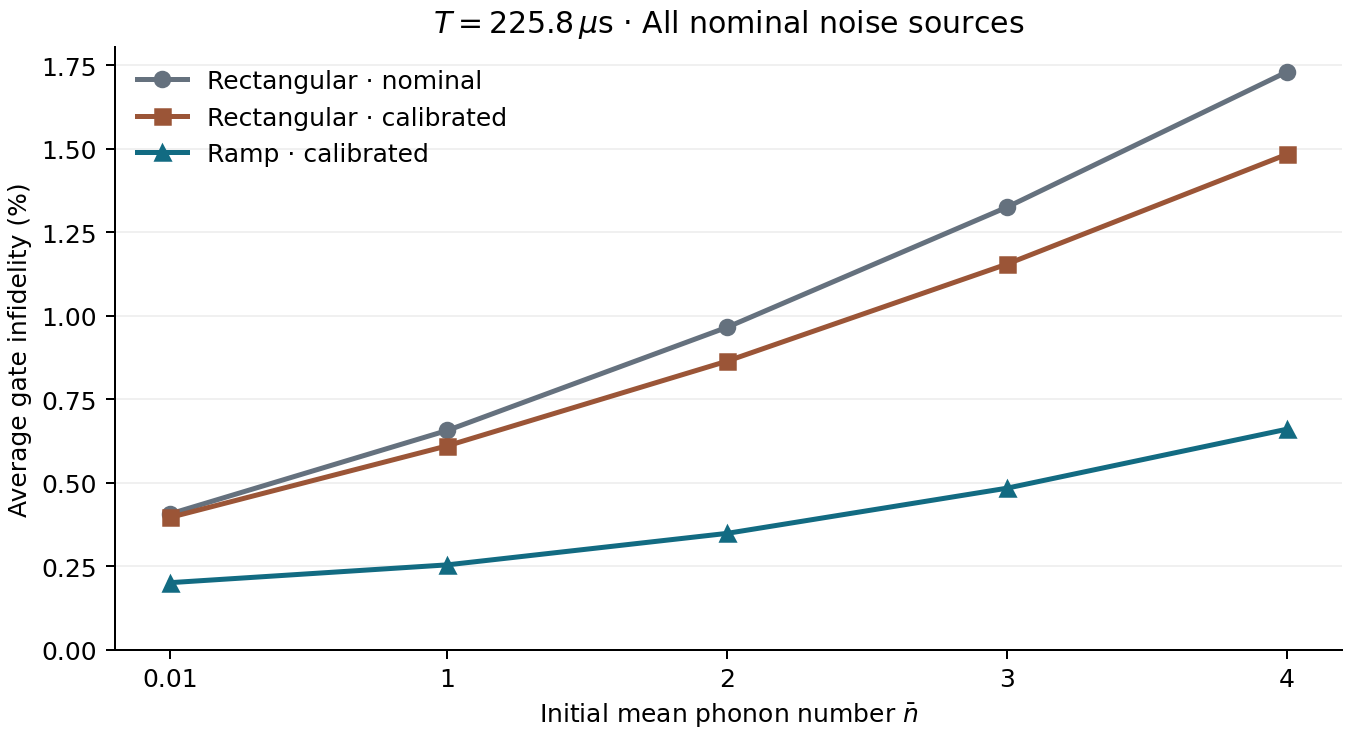

condition,Rectangular · nominal,Rectangular · calibrated,Ramp · calibrated
n_bar,,,
0.01,0.4074,0.3969,0.2014
1.00,0.6569,0.6109,0.2547
2.00,0.9656,0.8643,0.3489
3.00,1.3248,1.1545,0.4841
4.00,1.7293,1.4827,0.6604


In [18]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

sweep_dir = Path("results/matched_pulse_calibration_sweep")
pulse_sweep = pd.read_csv(sweep_dir / "summary.csv")
infidelities = pulse_sweep.pivot(index="n_bar", columns="condition", values="infidelity_percent").sort_index()
assert list(infidelities.index) == [0.01, 1, 2, 3, 4] and not infidelities.isna().any().any()
assert pulse_sweep.loc[pulse_sweep.condition != "standard_nominal", "hxx"].abs().max() <= 2e-3
styles = [
    ("standard_nominal", "Rectangular · nominal", "#65717e", "o"),
    ("standard", "Rectangular · calibrated", "#9b5537", "s"),
    ("smooth_detuning", "Ramp · calibrated", "#126b82", "^"),
]
fig, ax = plt.subplots(figsize=(7.5, 4.1), constrained_layout=True)
for key, label, color, marker in styles:
    ax.plot(infidelities.index, infidelities[key], label=label, color=color, marker=marker, lw=2)
ax.set_xticks(infidelities.index, ["0.01", "1", "2", "3", "4"])
ax.set_ylim(bottom=0)
ax.set(xlabel=r"Initial mean phonon number $\bar n$", ylabel="Average gate infidelity (%)",
       title=r"$T=225.8\,\mu$s · All nominal noise sources")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.18)
ax.spines[["top", "right"]].set_visible(False)
figure = sweep_dir / "three_condition_temperature_sweep.png"
fig.savefig(figure, dpi=180)
plt.close(fig)
display(Image(filename=str(figure), width=810))
display(infidelities[[key for key, *_ in styles]].rename(columns={key: label for key, label, *_ in styles}).round(4))


### 100 µs と 225.8 µs での温度依存性

横軸は初期平均フォノン数、縦軸は平均ゲート不忠実度（%）。波形ごとに、同じ温度で2つのゲート時間を比較する。100 µs ランプは225.8 µs ランプの全区間を $1/2.258$ 倍し、離調と公称駆動振幅を2.258倍した。この変換は理想モデルの無次元波形を保存する。矩形も両時間で1ループとし、$\delta/(2\pi)=1/T$、公称 $A/(2\pi)=1/(4T)$ とした。

各温度の較正済み条件は225.8 µs の較正倍率を初期値に使い、100 µs のQPTで $|h_{XX}|\leq 0.002$ rad/gate を確認した。両時間で温度ごとのフォノン次元と時間格子点数をそろえ、同じ物理散逸率（強度によらず一定の光散乱率）を用いた。短いゲートではより強いピーク駆動を許している。

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import smooth_detuning_analysis as s
import drive_calibration_qpt_analysis as q
from drive_amplitude_calibration import amplitude_update_from_hxx

def run_short_sweep():
    root = Path("results/matched_pulse_calibration_sweep")
    out = root / "100us"
    out.mkdir(exist_ok=True)
    reference = pd.read_csv(root/"summary.csv")
    smooth = s.SmoothDetuningConfigSI(delta_min_hz=22245.459873243974)
    duration = 100e-6
    ratio = smooth.gate_time_s / duration
    rect = s.StandardGateConfigSI(gate_time_s=duration, detuning_hz=1/duration, effective_sideband_hz=1/(4*duration))
    ramp = s.build_smooth_pulse_si(smooth, 1501)
    ramp["time_s"] /= ratio
    for field in ["A_rad_s","omega_rad_s","delta_rad_s"]:
        ramp[field] *= ratio
    rectangular = s.build_standard_pulse_si(rect,1501)
    rows = []
    for ref in reference.itertuples(index=False):
        n, name = ref.n_bar, ref.condition
        path = out / f"{name}_{n:g}.npz"
        pulse = ramp if name == "smooth_detuning" else rectangular
        if not path.exists():
            cfg = s.NbarSweepConfig(nbar_values=(n,),parallel_workers=6,show_progress=False)
            params = s._qpt_parameters(pulse, 5e-8/ratio, cfg, rect)
            scale = ref.amplitude_scale
            for iteration in range(4):
                params.update(A=scale*pulse["A_rad_s"],phonon_dim_override=int(ref.phonon_dim))
                chi = q.calculate_error_channel_batch((n,),params)[0]["chi"]
                hxx = q.extract_xx_generator_observables(chi)["h_XX_rad_per_gate"]
                if name == "standard_nominal" or abs(hxx) <= 2e-3:
                    break
                scale = amplitude_update_from_hxx(scale,hxx)
            else:
                raise RuntimeError(f"Calibration failed at {n}, {name}")
            np.savez_compressed(path,chi=chi,scale=scale,gate_time_s=duration)
        with np.load(path) as cache:
            obs=q.extract_xx_generator_observables(cache["chi"])
            rows.append(dict(n_bar=n,condition=name,amplitude_scale=float(cache["scale"]),hxx=obs["h_XX_rad_per_gate"],infidelity_percent=100*obs["average_infidelity"],gate_time_us=100.,phonon_dim=ref.phonon_dim))
        pd.DataFrame(rows).to_csv(out/"summary.csv",index=False)
        print(n,name,round(rows[-1]["infidelity_percent"],6),flush=True)

# run_short_sweep() で未計算の100 µsチャネルを計算し、集計表を再生成する。

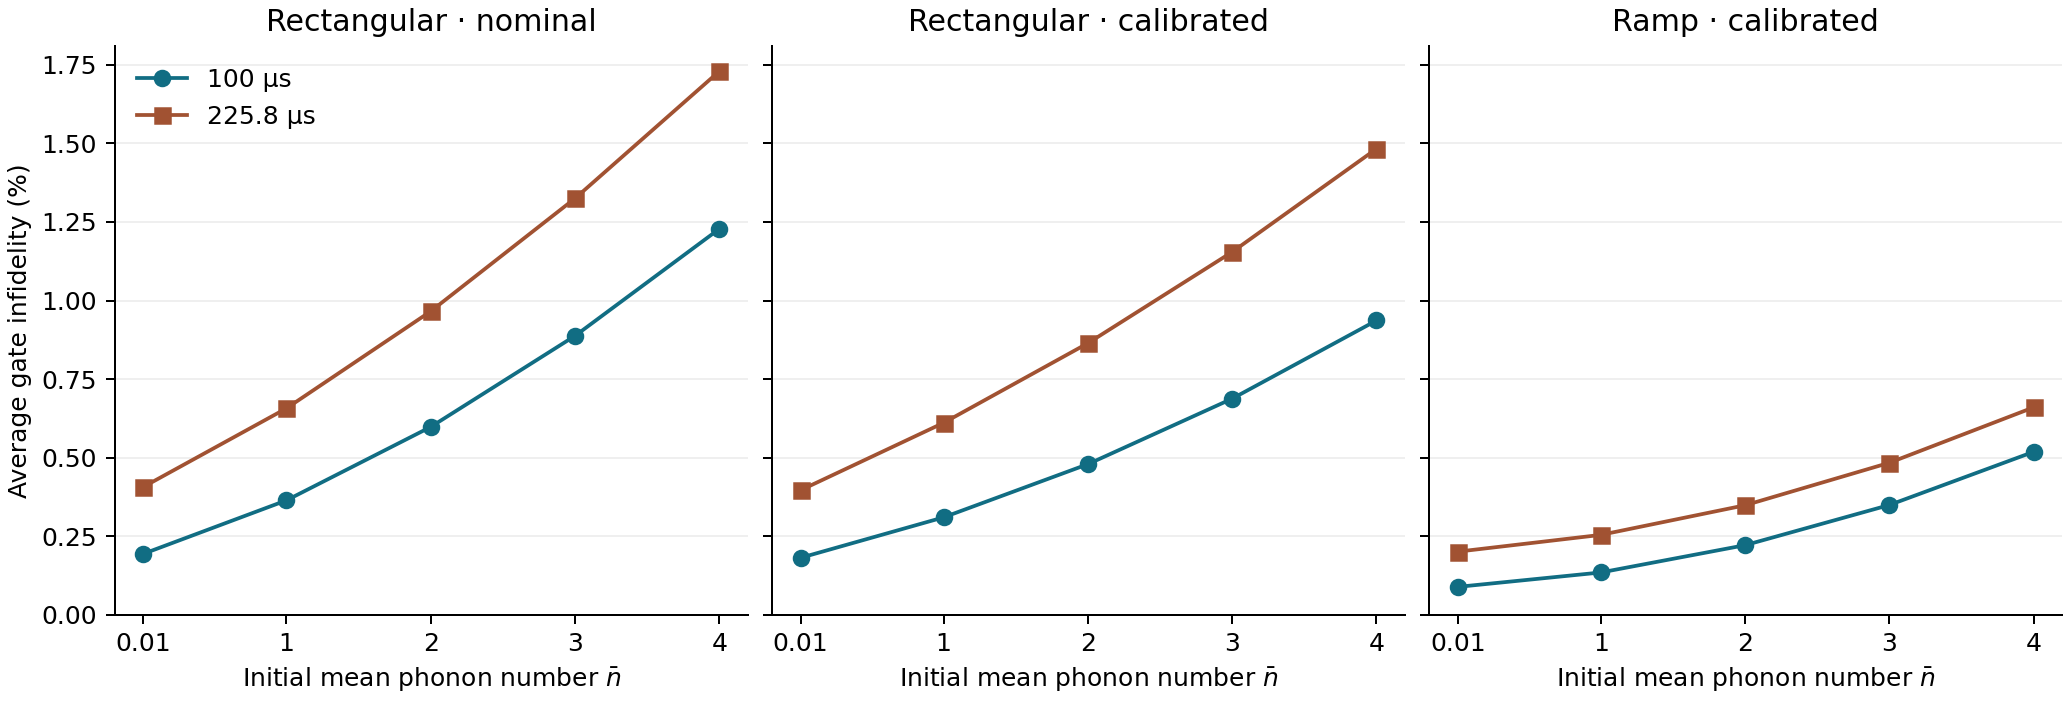

condition    standard_nominal         standard         smooth_detuning        
gate_time_us            100.0   225.8    100.0   225.8           100.0   225.8
n_bar                                                                         
0.01                   0.1946  0.4074   0.1819  0.3969          0.0894  0.2014
1.00                   0.3644  0.6569   0.3104  0.6109          0.1352  0.2547
2.00                   0.5980  0.9656   0.4796  0.8643          0.2219  0.3489
3.00                   0.8876  1.3248   0.6880  1.1545          0.3498  0.4841
4.00                   1.2279  1.7293   0.9366  1.4827          0.5190  0.6604

In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

sweep_dir = Path("results/matched_pulse_calibration_sweep")
comparison = pd.concat([pd.read_csv(sweep_dir / "100us" / "summary.csv"),
                        pd.read_csv(sweep_dir / "summary.csv")], ignore_index=True)
duration_table = comparison.pivot(index="n_bar", columns=["condition", "gate_time_us"],
                                  values="infidelity_percent").sort_index()
assert duration_table.shape == (5, 6) and not duration_table.isna().any().any()
assert comparison.loc[comparison.condition != "standard_nominal", "hxx"].abs().max() <= 2e-3
assert comparison.groupby(["n_bar", "condition"]).phonon_dim.nunique().eq(1).all()
conditions = [("standard_nominal", "Rectangular · nominal"),
              ("standard", "Rectangular · calibrated"),
              ("smooth_detuning", "Ramp · calibrated")]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9), sharey=True, constrained_layout=True)
for ax, (key, title) in zip(axes, conditions):
    for duration, color, marker in [(100., "#116d83", "o"), (225.8, "#a15232", "s")]:
        ax.plot(duration_table.index, duration_table[key, duration], color=color, marker=marker,
                label=f"{duration:g} µs")
    ax.set_title(title)
    ax.set_xticks(duration_table.index, ["0.01", "1", "2", "3", "4"])
    ax.set_xlabel(r"Initial mean phonon number $\bar n$")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Average gate infidelity (%)")
axes[0].set_ylim(bottom=0)
axes[0].legend(frameon=False)
figpath = sweep_dir / "infidelity_100us_vs_225p8us.png"
fig.savefig(figpath, dpi=180)
plt.close(fig)
display(Image(filename=str(figpath), width=1050))
duration_table = duration_table[[ (key,t) for key, _ in conditions for t in (100.,225.8) ]]
display(duration_table.round(4))


### 100 µsのパルス整形：不忠実度と誤差生成子

ノーマル（公称矩形）、駆動振幅のみ較正（矩形）、パルス整形＋振幅較正（ランプ）を比較する。3条件とも散逸率は同一で光散乱率は一定。較正振幅は温度ごとに選んだ。構造の比較では同じ温度・同じゲート時間の較正済み矩形を基準とする。$C_{XI,IX}=C_{IX,XI}$ は対称な相関生成子で、図表では既存コードの表記順を使う。

波形による変化は $\Delta c=c_{\rm ramp}-c_{\rm rect}$。低減率は $100(1-|c_{\rm ramp}|/|c_{\rm rect}|)$ で、正なら係数の絶対値が小さくなったことを表す。

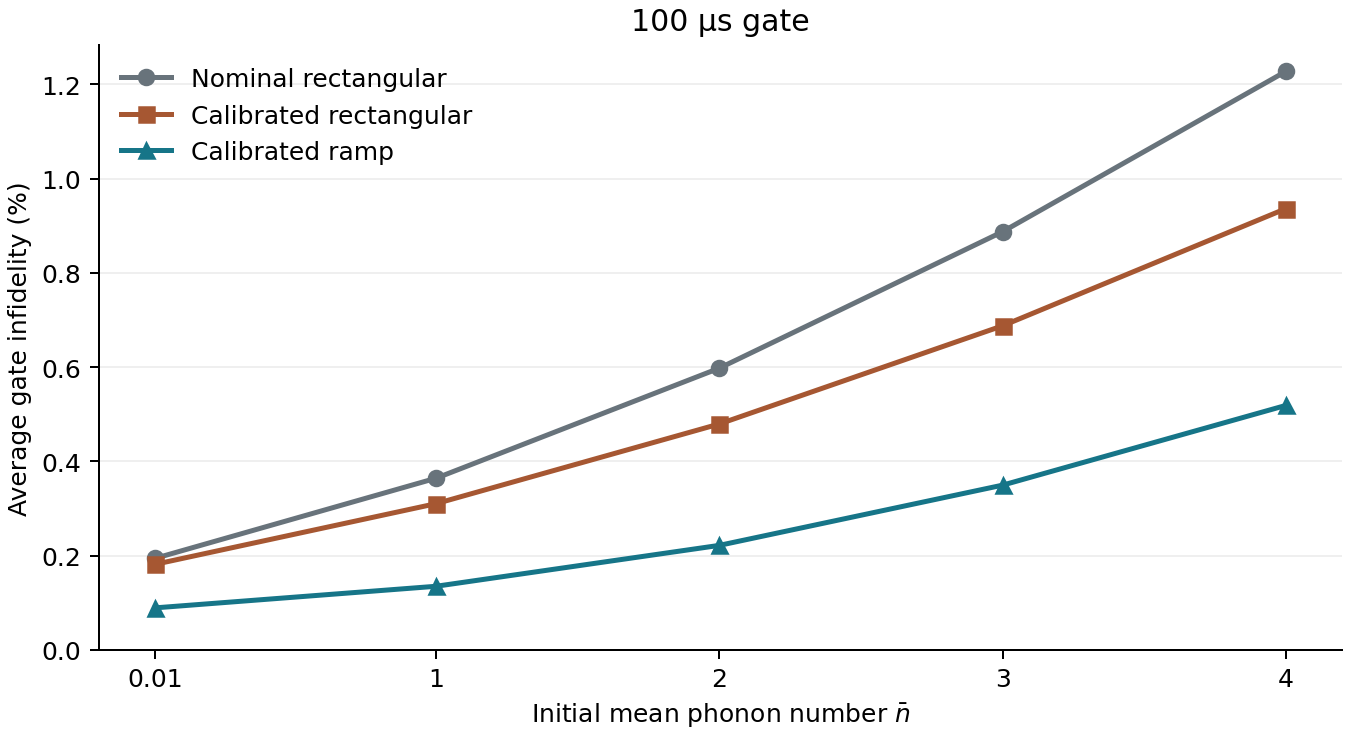

**指定3成分の比較（平均フォノン数4、係数は1ゲート当たり）**

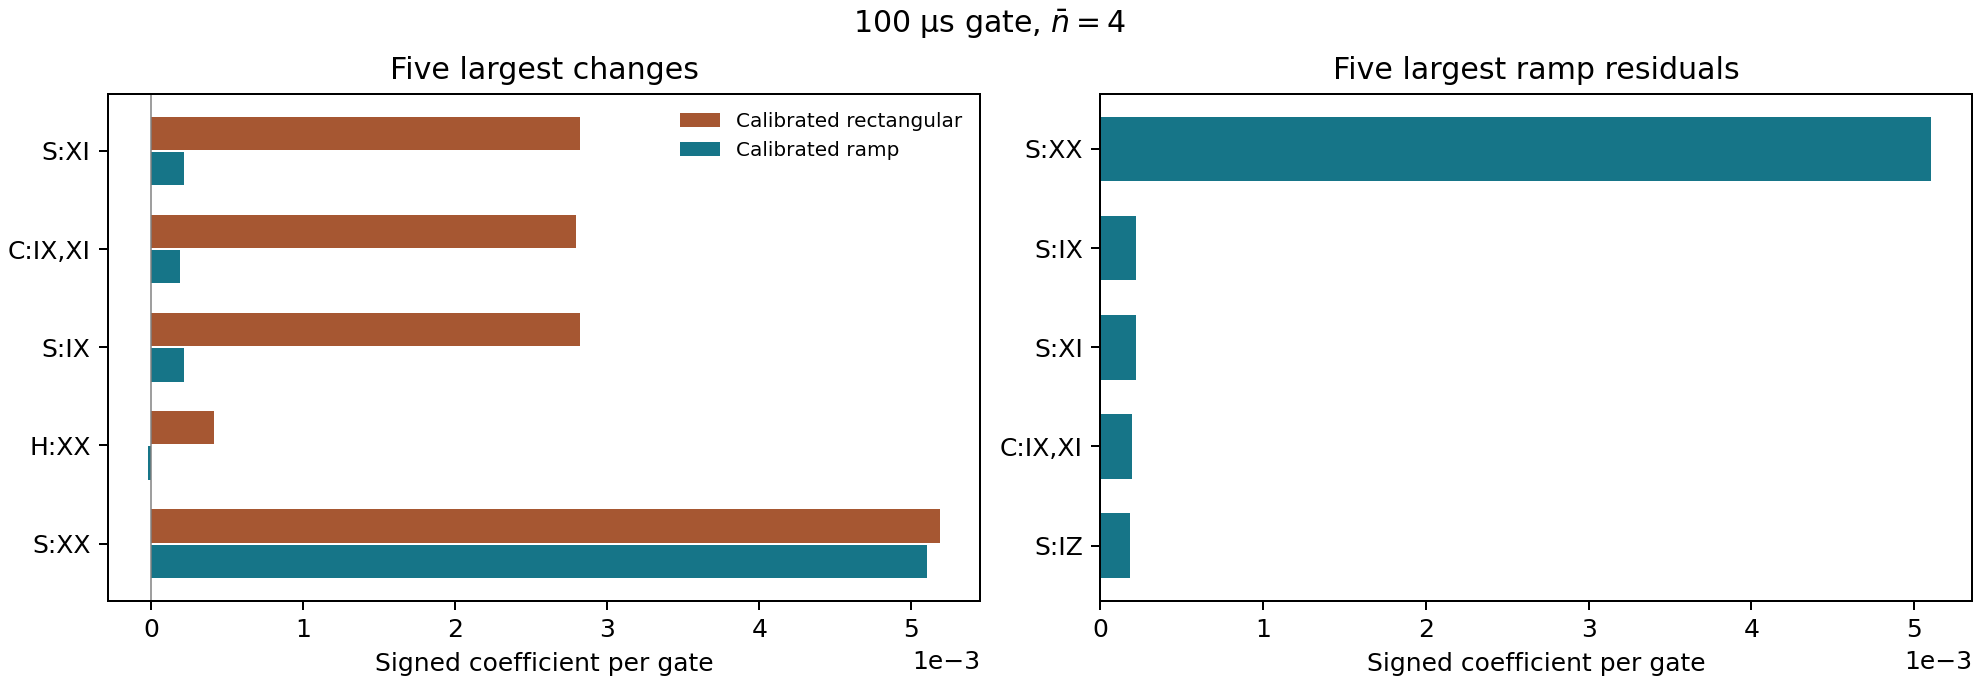

**100 µs・平均フォノン数4：変化量順と残留量順（表示値は符号付き）**

,変化した成分,Δc,残留成分,ランプの係数
1,S:XI,-2.602494e-03,S:XX,+5.104162e-03
2,"C:IX,XI",-2.602493e-03,S:IX,+2.171587e-04
3,S:IX,-2.602490e-03,S:XI,+2.171547e-04
4,H:XX,-4.371062e-04,"C:IX,XI",+1.921611e-04
5,S:XX,-8.668960e-05,S:IZ,+1.804089e-04


**各温度での低減率（%、同じゲート時間の較正済み矩形が基準）**

T (µs)  100.0                 225.8               
term     S:IX   S:XI C:IX,XI   S:IX   S:XI C:IX,XI
n_bar                                             
0.01    88.34  88.34   92.45  87.55  87.55   91.92
1.00    90.81  90.81   92.88  89.84  89.84   92.11
2.00    91.64  91.64   93.02  90.62  90.62   92.15
3.00    92.05  92.05   93.08  91.01  91.01   92.16
4.00    92.30  92.30   93.12  91.24  91.24   92.17

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import logm
from IPython.display import Image, Markdown, display
import noise_error_structure as ns
from drive_calibration_qpt_analysis import project_trace_normalized_chi_to_cptp

short_dir = Path("results/matched_pulse_calibration_sweep/100us")
pulse_summary = pd.read_csv(short_dir / "summary.csv")
groups = {"standard_nominal": "Nominal rectangular", "standard": "Calibrated rectangular",
          "smooth_detuning": "Calibrated ramp"}
rates = pulse_summary.pivot(index="n_bar", columns="condition", values="infidelity_percent")
assert rates.shape == (5, 3) and rates.notna().all().all()
fig, ax = plt.subplots(figsize=(7.5, 4.1), constrained_layout=True)
for (name, label), marker, color in zip(groups.items(), ["o", "s", "^"], ["#68737b", "#a65732", "#167588"]):
    ax.plot(rates.index, rates[name], marker=marker, color=color, label=label, lw=2)
ax.set_xticks(rates.index, [f"{n:g}" for n in rates.index])
ax.set(xlabel=r"Initial mean phonon number $\bar n$", ylabel="Average gate infidelity (%)",
       title="100 µs gate", ylim=(0, None))
ax.grid(axis="y", alpha=.2)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(short_dir / "infidelity_three_conditions.png", dpi=180)
plt.close(fig)
display(Image(filename=str(short_dir / "infidelity_three_conditions.png"), width=770))

def read_pulse_coefficients(path, duration):
    with np.load(path) as data:
        assert np.isclose(float(data["gate_time_s"])*1e6, duration)
        channel, _, _ = project_trace_normalized_chi_to_cptp(data["chi"])
    generator = logm(ns.mg.superoperator_to_ptm(channel))
    assert np.linalg.norm(generator.imag) < 1e-8
    decomposition = ns._decompose_generator_taxonomy(generator.real)
    coefficients = pd.Series(decomposition["coefficients"], index=[
        f"{sector}:{mode}" for sector, mode in decomposition["metadata"]])
    assert len(coefficients) == 240 and abs(coefficients["H:XX"]) <= 2e-3
    return coefficients

selected = ["S:XI", "S:IX", "C:IX,XI"]
pulse_tables = {}
for duration in (100., 225.8):
    for n in rates.index:
        if duration == 100:
            folder, suffix = short_dir, f"_{n:g}"
        elif n == 4:
            folder, suffix = Path("results/matched_pulse_calibration_nbar4"), ""
        else:
            folder, suffix = short_dir.parent, "_" + str(float(n)).replace(".", "p")
        pair = pd.DataFrame({groups[key]: read_pulse_coefficients(folder / f"{key}{suffix}.npz", duration)
                             for key in ("standard", "smooth_detuning")})
        pair.columns = ["Rectangular", "Ramp"]
        pair["Change"] = pair.Ramp - pair.Rectangular
        pulse_tables[duration, n] = pair
structure = pd.concat(pulse_tables, names=["T (µs)", "n_bar", "term"])
targets = structure.loc[structure.index.get_level_values("term").isin(selected)].copy()
targets["Reduction (%)"] = 100*(1 - targets.Ramp.abs()/targets.Rectangular.abs())
display(Markdown("**指定3成分の比較（平均フォノン数4、係数は1ゲート当たり）**"))
display(targets.xs(4, level="n_bar").style.format({k:"{:+.5e}" for k in ["Rectangular","Ramp","Change"]} |
                                                   {"Reduction (%)":"{:.2f}"}))
example = pulse_tables[100., 4.]
changed = example.loc[example.Change.abs().nlargest(5).index]
remaining = example.Ramp.loc[example.Ramp.abs().nlargest(5).index]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
y = np.arange(5)
ax.barh(y-.18, changed.Rectangular, .34, label="Calibrated rectangular", color="#a65732")
ax.barh(y+.18, changed.Ramp, .34, label="Calibrated ramp", color="#167588")
ax.set_yticks(y, changed.index)
ax.legend(frameon=False, fontsize=8)
ax.set_title("Five largest changes")
bx.barh(y, remaining, .65, color="#167588")
bx.set_yticks(y, remaining.index)
bx.set_title("Five largest ramp residuals")
for panel in (ax,bx):
    panel.invert_yaxis()
    panel.axvline(0, color="0.5", lw=.6)
    panel.set_xlabel("Signed coefficient per gate")
    panel.ticklabel_format(style="sci",axis="x",scilimits=(-2,2))
fig.suptitle(r"100 µs gate, $\bar n=4$")
fig.savefig(short_dir / "error_structure_top5.png", dpi=180)
plt.close(fig)
display(Image(filename=str(short_dir / "error_structure_top5.png"), width=1020))
display(Markdown("**100 µs・平均フォノン数4：変化量順と残留量順（表示値は符号付き）**"))
ranking = pd.DataFrame({"変化した成分":changed.index, "Δc":changed.Change.values,
                        "残留成分":remaining.index, "ランプの係数":remaining.values},index=range(1,6))
display(ranking.style.format({"Δc":"{:+.6e}", "ランプの係数":"{:+.6e}"}))
display(Markdown("**各温度での低減率（%、同じゲート時間の較正済み矩形が基準）**"))
display(targets["Reduction (%)"].unstack(["T (µs)", "term"]).round(2))


## 100 µsのBowers型ランプと較正済み矩形の比較

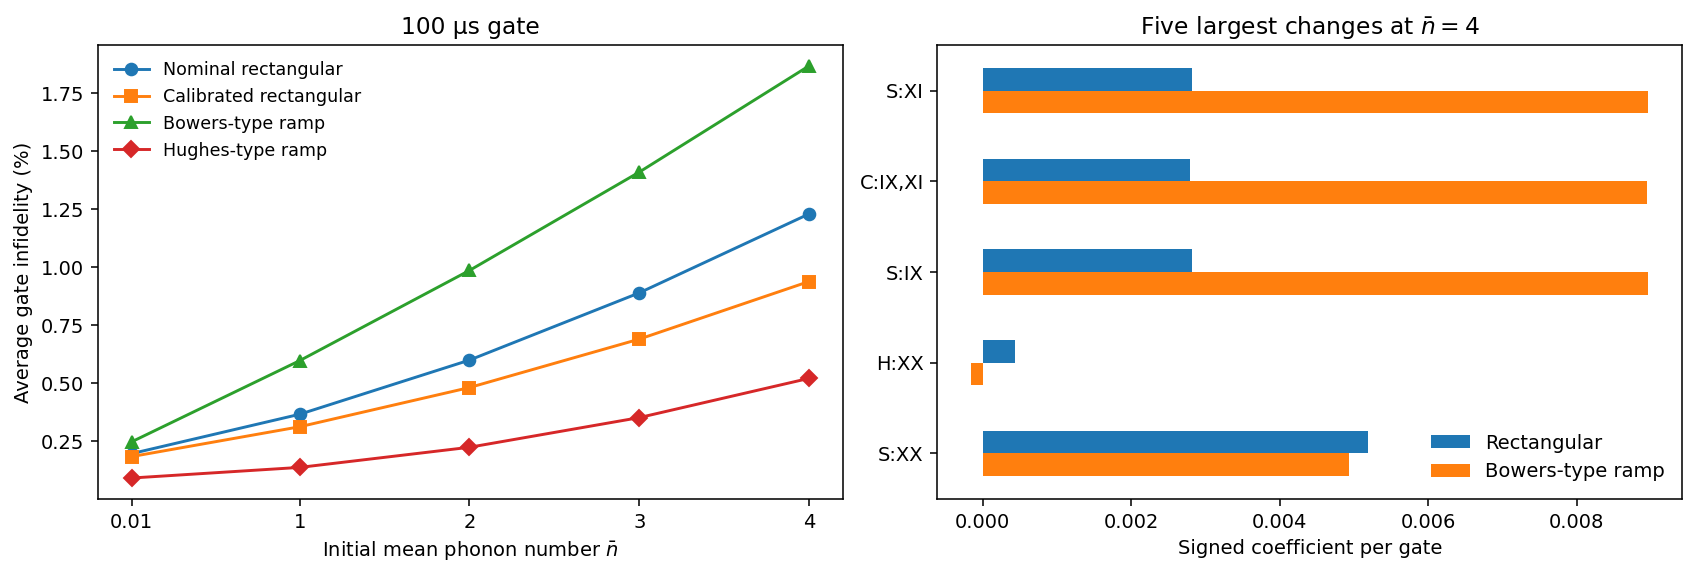

condition,Bowers-type ramp,Calibrated rectangular,Nominal rectangular,Hughes-type ramp
n_bar,,,,
0.01,0.2456,0.1819,0.1946,0.0894
1.00,0.5956,0.3104,0.3644,0.1352
2.00,0.9844,0.4795,0.5978,0.2219
3.00,1.4082,0.6882,0.8876,0.3498
4.00,1.8662,0.9366,1.2279,0.5190


,変化した成分,符号付き変化量,残留成分,符号付き残留係数
1,S:XI,0.006147,S:XI,0.008966
2,"C:IX,XI",0.006147,S:IX,0.008966
3,S:IX,0.006146,"C:IX,XI",0.008941
4,H:XX,-0.000586,S:XX,0.004939
5,S:XX,-0.000252,S:XY,0.000208


In [21]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

bowers_dir = Path("results/bowers_ramped_ms")
bowers = pd.read_csv(bowers_dir / "summary.csv")
hughes = pd.read_csv("results/matched_pulse_calibration_sweep/100us/summary.csv")
rates = bowers.pivot(index="n_bar", columns="condition", values="infidelity_percent").rename(
    columns={"rect_nominal":"Nominal rectangular", "rect_calibrated":"Calibrated rectangular",
             "ramp_calibrated":"Bowers-type ramp"})
rates["Hughes-type ramp"] = hughes.loc[hughes.condition == "smooth_detuning"].set_index("n_bar").infidelity_percent
assert rates.shape == (5, 4) and rates.notna().all().all()
terms = pd.read_csv(bowers_dir / "hsca.csv")
t = terms.loc[terms.n_bar == 4].pivot(index="term", columns="condition", values="coefficient")
change = t.ramp_calibrated - t.rect_calibrated
largest = change.abs().nlargest(5).index
residual = t.ramp_calibrated.abs().nlargest(5).index
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for key, marker in zip(["Nominal rectangular","Calibrated rectangular","Bowers-type ramp","Hughes-type ramp"], ["o","s","^","D"]):
    a.plot(rates.index,rates[key],marker=marker,label=key)
a.set(xlabel=r"Initial mean phonon number $\bar n$",ylabel="Average gate infidelity (%)", title="100 µs gate")
a.set_xticks(rates.index,["0.01","1","2","3","4"])
a.legend(frameon=False,fontsize=9)
t.loc[largest,["rect_calibrated","ramp_calibrated"]].rename(columns={"rect_calibrated":"Rectangular","ramp_calibrated":"Bowers-type ramp"}).plot.barh(ax=b)
b.invert_yaxis()
b.set(xlabel="Signed coefficient per gate",ylabel="",title=r"Five largest changes at $\bar n=4$")
b.legend(frameon=False)
display(fig)
plt.close(fig)
display(rates.round(4))
display(pd.DataFrame({"変化した成分":largest,"符号付き変化量":change.loc[largest].values,
                      "残留成分":residual,"符号付き残留係数":t.ramp_calibrated.loc[residual].values},index=range(1,6)))


## Hughes 型ランプの誤差チャネルと Pauli twirling

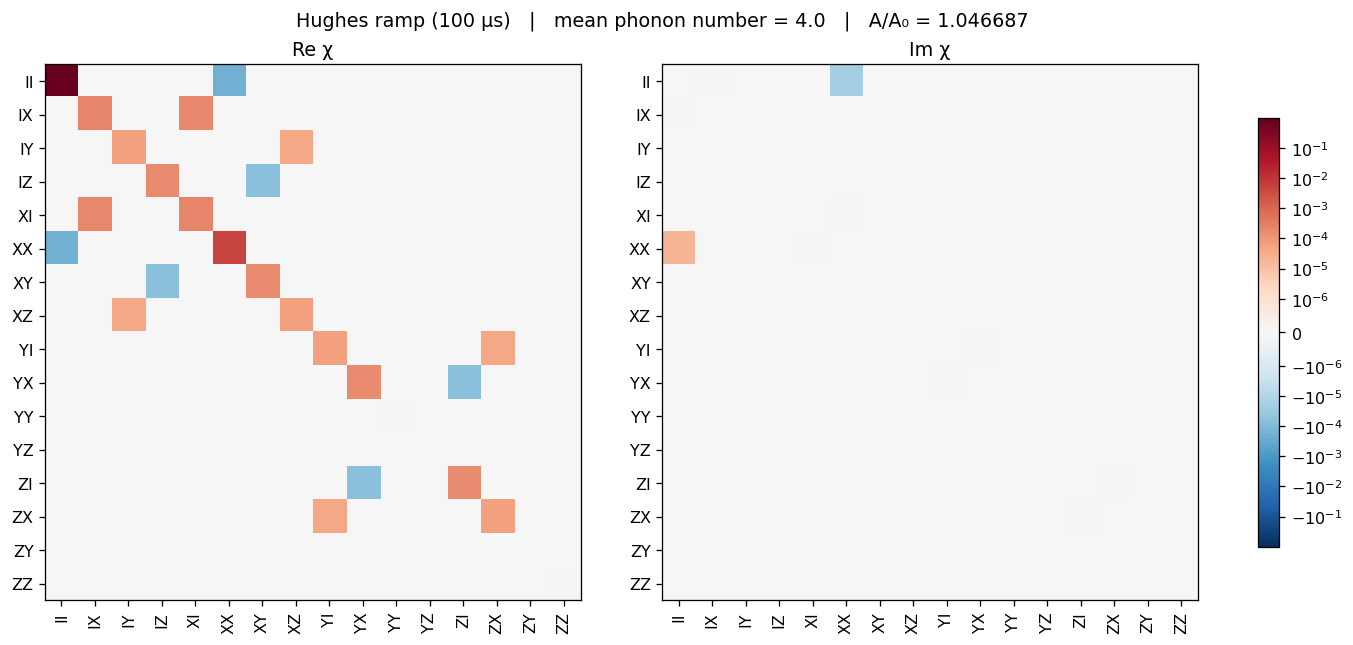

In [1]:
MEAN_PHONON_NUMBER = 4.0

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from io import BytesIO
from IPython.display import Image, display
from ms_gate_functions import pauli_labels_and_weights

def pulse_error_chi(n_bar, condition):
    if condition not in ("smooth_detuning", "standard_nominal", "standard"):
        raise ValueError(f"Unknown pulse condition: {condition}")
    n_bar = float(n_bar)
    if not np.isfinite(n_bar) or n_bar < 0:
        raise ValueError("Mean phonon number must be finite and non-negative.")
    folder = Path("results/matched_pulse_calibration_sweep/100us")
    for path in folder.glob("*.npz"):
        pulse_name, _, value = path.stem.rpartition("_")
        if pulse_name == condition and float(value) == n_bar:
            with np.load(path) as data:
                return data["chi"], float(data["scale"])

    import smooth_detuning_analysis as s
    import drive_calibration_qpt_analysis as q
    from drive_amplitude_calibration import amplitude_update_from_hxx

    config = s.SmoothDetuningConfigSI(delta_min_hz=22245.459873243974)
    reference = s.StandardGateConfigSI(gate_time_s=100e-6)
    ratio = config.gate_time_s / reference.gate_time_s
    if condition == "smooth_detuning":
        pulse = s.build_smooth_pulse_si(config, 1501)
        pulse["time_s"] /= ratio
        for field in ("A_rad_s", "omega_rad_s", "delta_rad_s"):
            pulse[field] *= ratio
    else:
        pulse = s.build_standard_pulse_si(reference, 1501)
    sweep = s.NbarSweepConfig(nbar_values=(n_bar,), show_progress=False)
    params = s._qpt_parameters(pulse, 5e-8 / ratio, sweep, reference)
    scale = 1.0
    for _ in range(4):
        params["A"] = scale * pulse["A_rad_s"]
        chi = q.calculate_error_channel_batch((n_bar,), params)[0]["chi"]
        if condition == "standard_nominal":
            return chi, scale
        hxx = q.extract_xx_generator_observables(chi)["h_XX_rad_per_gate"]
        if abs(hxx) <= 2e-3:
            return chi, scale
        scale = amplitude_update_from_hxx(scale, hxx)
    raise RuntimeError(f"Amplitude calibration did not converge at n_bar={n_bar}.")

def hughes_error_chi(n_bar):
    return pulse_error_chi(n_bar, "smooth_detuning")

hughes_chi, hughes_scale = hughes_error_chi(MEAN_PHONON_NUMBER)
labels = [label for label, _ in pauli_labels_and_weights()]
limit = np.abs(hughes_chi).max()
norm = SymLogNorm(linthresh=1e-6, vmin=-limit, vmax=limit)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
for ax, part, title in zip(axes, (hughes_chi.real, hughes_chi.imag), ("Re χ", "Im χ")):
    mesh = ax.imshow(part, cmap="RdBu_r", norm=norm)
    ax.set_xticks(range(16), labels, rotation=90)
    ax.set_yticks(range(16), labels)
    ax.set_title(title)
fig.colorbar(mesh, ax=axes, shrink=0.8)
fig.suptitle(f"Hughes ramp (100 µs)   |   mean phonon number = {MEAN_PHONON_NUMBER}   |   A/A₀ = {hughes_scale:.6f}")
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=115, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
plt.close(fig)

### 矩形波を基準にした χ 行列の差分

上のセルと同じ平均フォノン数、ゲート時間 100 µs、全ノイズ ON で比較する。上段は Hughes 型 − 公称振幅の矩形波、下段は Hughes 型 − 同じ平均フォノン数で振幅を較正した矩形波。左列は実部、右列は虚部で、4面とも共通の符号付き色尺度を使う。

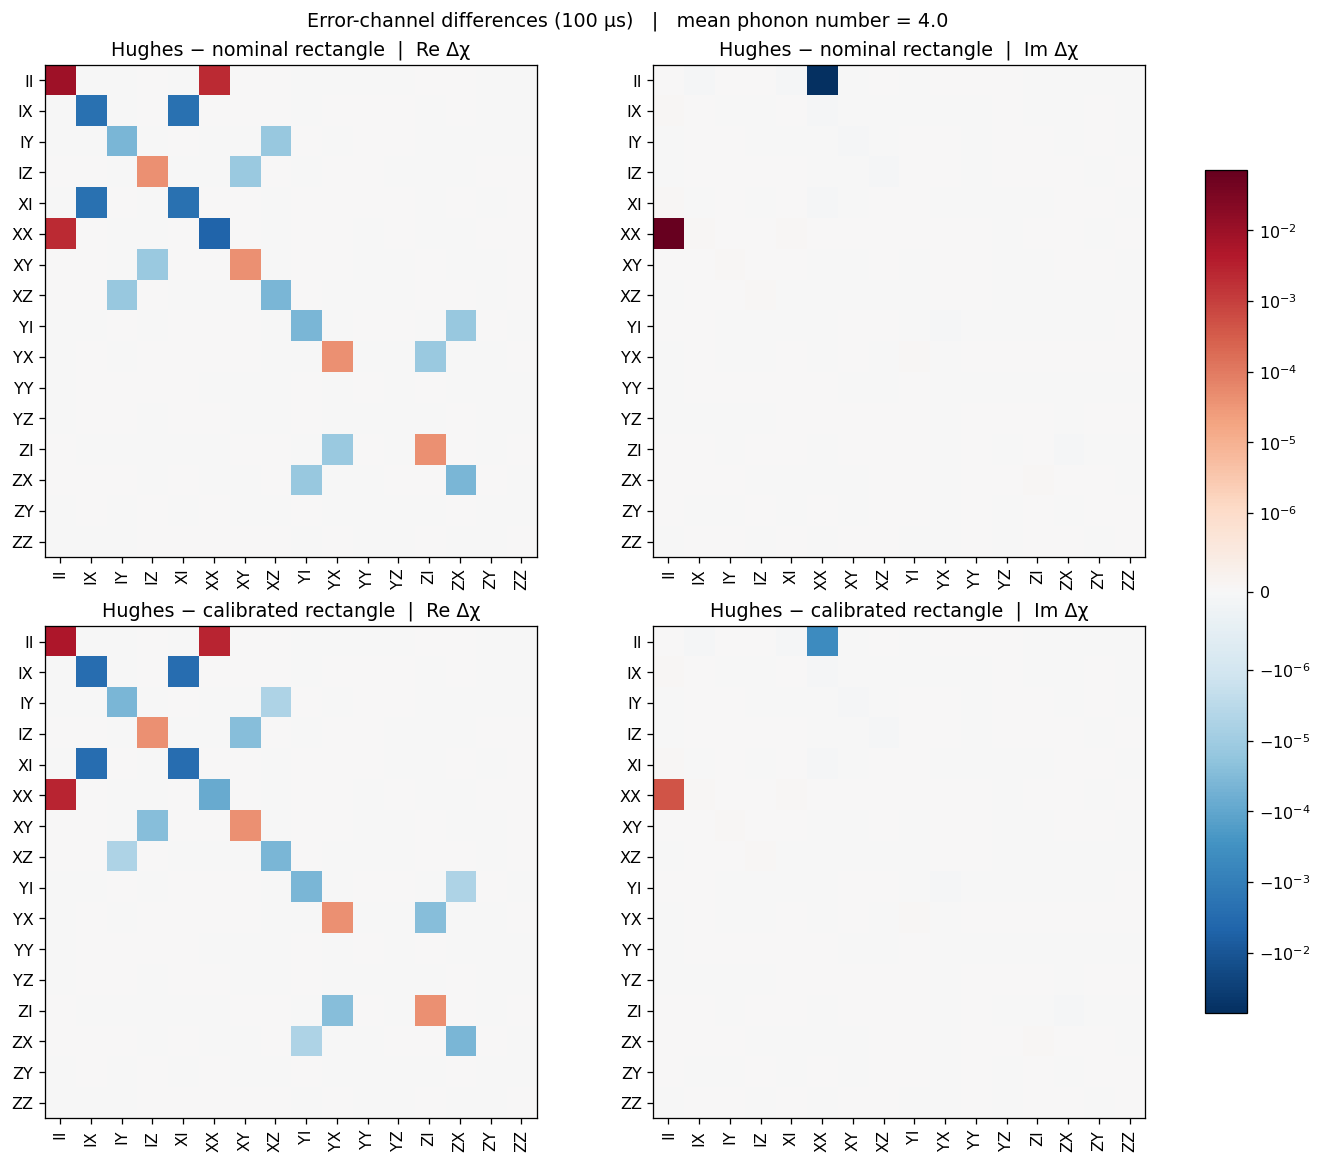

In [2]:
rect_nominal_chi, _ = pulse_error_chi(MEAN_PHONON_NUMBER, "standard_nominal")
rect_calibrated_chi, _ = pulse_error_chi(MEAN_PHONON_NUMBER, "standard")
delta_chi_nominal = hughes_chi - rect_nominal_chi
delta_chi_calibrated = hughes_chi - rect_calibrated_chi

comparisons = [("Hughes − nominal rectangle", delta_chi_nominal),
               ("Hughes − calibrated rectangle", delta_chi_calibrated)]
limit = max(np.abs(delta).max() for _, delta in comparisons)
norm = SymLogNorm(linthresh=1e-6, vmin=-limit, vmax=limit)
fig, axes = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")
for row, (name, delta) in zip(axes, comparisons):
    for ax, part, title in zip(row, (delta.real, delta.imag), ("Re Δχ", "Im Δχ")):
        mesh = ax.imshow(part, cmap="RdBu_r", norm=norm)
        ax.set_xticks(range(len(labels)), labels, rotation=90)
        ax.set_yticks(range(len(labels)), labels)
        ax.set_title(f"{name}  |  {title}")
fig.colorbar(mesh, ax=axes, shrink=0.8)
fig.suptitle(f"Error-channel differences (100 µs)   |   mean phonon number = {MEAN_PHONON_NUMBER}")
with BytesIO() as buffer:
    fig.savefig(buffer, format="png", dpi=115, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
plt.close(fig)

### χ 行列の差分の全要素ランキング

比較ごとに、直上の図の全256要素を $|\Delta\chi_{ij}|$ の降順に示す。行・列は図と同じ Pauli 基底で、上三角と下三角の両方を含む。

In [3]:
import pandas as pd
from IPython.display import HTML, display

for name, delta in comparisons:
    values = delta.ravel()
    pairs = pd.MultiIndex.from_product([labels, labels], names=["行", "列"])
    table = pd.DataFrame({
        "|Δχ|": np.abs(values),
        "Re Δχ": values.real,
        "Im Δχ": values.imag,
    }, index=pairs).reset_index()
    table = table.sort_values("|Δχ|", ascending=False, kind="stable")
    table.index = pd.RangeIndex(1, len(table) + 1, name="順位")
    heading = f"{name}（平均フォノン数 {MEAN_PHONON_NUMBER:g}）"
    display(HTML(f"<h4>{heading}</h4>" + table.to_html(float_format="{:.8e}".format, max_rows=None)))

,行,列,|Δχ|,Re Δχ,Im Δχ
順位,,,,,
1,II,XX,7.14495965e-02,2.23297278e-03,-7.14146951e-02
2,XX,II,7.14495965e-02,2.23297278e-03,7.14146951e-02
3,II,II,8.86153490e-03,8.86153490e-03,1.03870055e-18
4,XX,XX,4.39556753e-03,-4.39556753e-03,-8.33898262e-19
5,XI,XI,2.23298566e-03,-2.23298566e-03,2.67109522e-18
6,IX,IX,2.23298171e-03,-2.23298171e-03,2.01089625e-17
7,IX,XI,2.23297278e-03,-2.23297278e-03,5.38848577e-09
8,XI,IX,2.23297278e-03,-2.23297278e-03,-5.38848572e-09
9,XZ,XZ,4.18940803e-05,-4.18940803e-05,-1.13833117e-17


,行,列,|Δχ|,Re Δχ,Im Δχ
順位,,,,,
1,II,II,5.21999748e-03,5.21999748e-03,3.58125047e-18
2,XX,II,2.60456303e-03,2.56884786e-03,4.29847928e-04
3,II,XX,2.60456303e-03,2.56884786e-03,-4.29847928e-04
4,XI,XI,2.56886107e-03,-2.56886107e-03,3.08833989e-18
5,IX,IX,2.56885711e-03,-2.56885711e-03,1.79918846e-17
6,IX,XI,2.56884786e-03,-2.56884786e-03,5.38848581e-09
7,XI,IX,2.56884786e-03,-2.56884786e-03,-5.38848575e-09
8,XX,XX,8.22793032e-05,-8.22793032e-05,7.70177247e-18
9,XZ,XZ,4.25794756e-05,-4.25794756e-05,-1.12621103e-17


## 100 µs における Pauli 近似の許容範囲

各条件・各 $\bar n$ の保存済み post-gate 誤差チャネルを、そのチャネル自身の Pauli twirl と比較する。校正条件では各 $\bar n$ で駆動強度を個別に調整している。表は生存誤り率の絶対差を確率単位で示す。符号付きの差 $\delta r=r_{\rm full}-r_{\rm P}$ が正なら、Pauli 近似は誤り率を過小評価する。

許容幅の例を $10^{-3}$（0.1 パーセントポイント）とする。下のセルの `bell_tolerance` を変えて再実行すると、両ベル状態で許容幅に収まる計算点を確認できる。判定は保存された数値に基づき、点間の補間や数値収束誤差を含まない。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

bell_tolerance = 1e-3
bell_dir = Path("results/matched_pulse_calibration_sweep/100us")
bell_conditions = {
    "standard_nominal": "ノーマル",
    "standard": "駆動強度校正",
    "smooth_detuning": "駆動強度校正＋パルス整形",
}
# Pauli 期待値が非零の成分は II, XX, YY, ZZ のみ。
bell_indices = [0, 5, 10, 15]
bell_signs = {"Φ+": np.array([1, 1, -1, 1]), "Ψ−": np.array([1, -1, -1, -1])}
bell_rows = []
for point in pd.read_csv(bell_dir / "summary.csv").itertuples():
    with np.load(bell_dir / f"{point.condition}_{point.n_bar:g}.npz") as cache:
        assert np.isclose(float(cache["gate_time_s"]), 100e-6)
        block = cache["chi"][np.ix_(bell_indices, bell_indices)]
    r_pauli = 1 - block.trace().real
    row = {"条件": bell_conditions[point.condition], "n̄": point.n_bar, "r Pauli（共通）": r_pauli}
    for state, signs in bell_signs.items():
        r_full = 1 - (signs @ block @ signs).real
        row[f"r full {state}"] = r_full
        row[f"δr {state}"] = r_full - r_pauli
    row["最大絶対差"] = max(abs(row[f"δr {state}"]) for state in bell_signs)
    row["判定"] = "範囲内" if row["最大絶対差"] <= bell_tolerance else "範囲外"
    bell_rows.append(row)

bell_results = pd.DataFrame(bell_rows)
print(f"100 µs ｜ 許容幅 {bell_tolerance:g} ｜ 確認した平均フォノン数")
for condition in bell_conditions.values():
    passed = bell_results[(bell_results["条件"] == condition) & (bell_results["判定"] == "範囲内")]
    print(condition, "：", ", ".join(f"{n:g}" for n in passed["n̄"]) or "該当点なし")
display(bell_results.round(8))

100 µs ｜ 許容幅 0.001 ｜ 確認した平均フォノン数
ノーマル ： 該当点なし
駆動強度校正 ： 該当点なし
駆動強度校正＋パルス整形 ： 0.01, 1, 2, 3, 4


,条件,n̄,r Pauli（共通）,r full Φ+,δr Φ+,r full Ψ−,δr Ψ−,最大絶対差,判定
0,ノーマル,0.01,0.002080,0.003128,0.001048,0.001032,-0.001048,0.001048,範囲外
1,駆動強度校正,0.01,0.002103,0.003174,0.001071,0.001032,-0.001071,0.001071,範囲外
2,駆動強度校正＋パルス整形,0.01,0.001113,0.001194,0.000081,0.001032,-0.000081,0.000081,範囲内
3,ノーマル,1.00,0.003112,0.005192,0.002080,0.001033,-0.002080,0.002080,範囲外
4,駆動強度校正,1.00,0.003216,0.005399,0.002183,0.001033,-0.002183,0.002183,範囲外
5,駆動強度校正＋パルス整形,1.00,0.001189,0.001345,0.000156,0.001032,-0.000156,0.000156,範囲内
6,ノーマル,2.00,0.004094,0.007155,0.003061,0.001033,-0.003061,0.003061,範囲外
7,駆動強度校正,2.00,0.004334,0.007636,0.003302,0.001033,-0.003302,0.003302,範囲外
8,駆動強度校正＋パルス整形,2.00,0.001265,0.001497,0.000232,0.001032,-0.000232,0.000232,範囲内
9,ノーマル,3.00,0.005014,0.008996,0.003982,0.001033,-0.003982,0.003982,範囲外


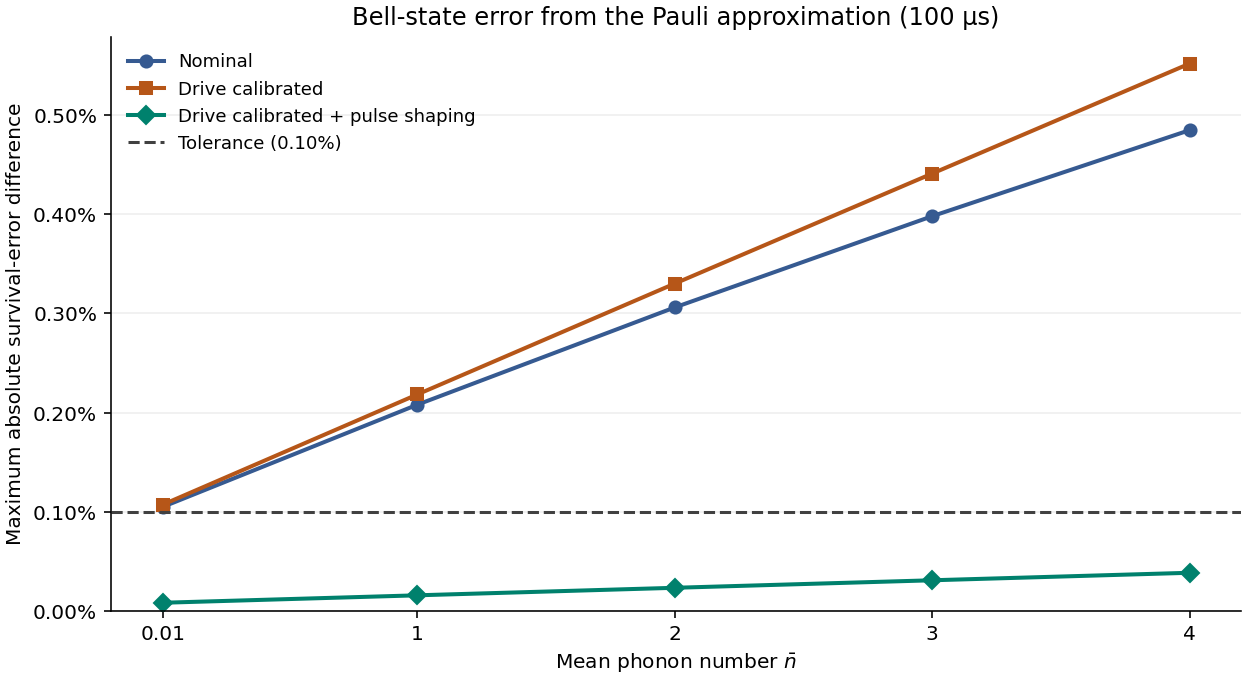

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig_bell, ax_bell = plt.subplots(figsize=(8.6, 4.7), constrained_layout=True)
styles = [
    ("Nominal", "#365a91", "o"),
    ("Drive calibrated", "#b65618", "s"),
    ("Drive calibrated + pulse shaping", "#00816d", "D"),
]
for condition, (label, color, marker) in zip(bell_conditions.values(), styles):
    points = bell_results[bell_results["条件"] == condition].sort_values("n̄")
    ax_bell.plot(points["n̄"], points["最大絶対差"], color=color, marker=marker,
                 linewidth=2, markersize=6, label=label)

ax_bell.axhline(bell_tolerance, color="#414141", linestyle="--",
                label=f"Tolerance ({bell_tolerance:.2%})")
ax_bell.set(xlabel=r"Mean phonon number $\bar{n}$",
            ylabel="Maximum absolute survival-error difference",
            title="Bell-state error from the Pauli approximation (100 µs)",
            ylim=(0, None))
ax_bell.set_xticks([0.01, 1, 2, 3, 4], labels=["0.01", "1", "2", "3", "4"])
ax_bell.yaxis.set_major_formatter(PercentFormatter(1, decimals=2))
ax_bell.grid(axis="y", alpha=0.22)
ax_bell.spines[["top", "right"]].set_visible(False)
ax_bell.legend(frameon=False, fontsize=9)
plt.show()

### Contribution of the collective cross component（100 µs）

保存された誤差チャネルから求めた $w=(\mathrm{Re}\,\chi_{IX,XI}-\mathrm{Re}\,\chi_{II,XX})/2$ と、ベル状態の生存誤り率への寄与を比較する。集団項は Φ+ で $+2w$、Ψ− で $-2w$。残差は実際の符号付き予測差から集団項を引いた値で、表はすべて確率単位。

In [3]:
# χ の Pauli 基底順序は II, IX, IY, IZ, XI, XX, ... 。
cross_rows = []
actual = bell_results.set_index(["条件", "n̄"])
for point in pd.read_csv(bell_dir / "summary.csv").itertuples():
    condition = bell_conditions[point.condition]
    with np.load(bell_dir / f"{point.condition}_{point.n_bar:g}.npz") as cache:
        chi = cache["chi"]
        w = (chi[1, 4].real - chi[0, 5].real) / 2
    row = {"条件": condition, "n̄": point.n_bar, "w": w}
    for state, prediction in [("Φ+", 2*w), ("Ψ−", -2*w)]:
        observed = actual.loc[(condition, point.n_bar), f"δr {state}"]
        row[f"δr {state}"] = observed
        row[f"集団項 {state}"] = prediction
        row[f"残差 {state}"] = observed - prediction
    cross_rows.append(row)

cross_results = pd.DataFrame(cross_rows)
display(cross_results.style.format({col: "{:.6e}" for col in cross_results.columns[2:]}))

,条件,n̄,w,δr Φ+,集団項 Φ+,残差 Φ+,δr Ψ−,集団項 Ψ−,残差 Ψ−
0,ノーマル,0.010000,5.239669e-04,1.047947e-03,1.047934e-03,1.323081e-08,-1.047947e-03,-1.047934e-03,-1.323081e-08
1,駆動強度校正,0.010000,5.352504e-04,1.070514e-03,1.070501e-03,1.315831e-08,-1.070514e-03,-1.070501e-03,-1.315831e-08
2,駆動強度校正＋パルス整形,0.010000,4.048864e-05,8.097451e-05,8.097729e-05,-2.780878e-09,-8.097591e-05,-8.097729e-05,1.373827e-09
3,ノーマル,1.000000,1.039989e-03,2.079987e-03,2.079979e-03,8.475276e-09,-2.079987e-03,-2.079979e-03,-8.475275e-09
4,駆動強度校正,1.000000,1.091706e-03,2.183420e-03,2.183412e-03,8.338685e-09,-2.183420e-03,-2.183412e-03,-8.338685e-09
5,駆動強度校正＋パルス整形,1.000000,7.808567e-05,1.561671e-04,1.561713e-04,-4.268084e-09,-1.561695e-04,-1.561713e-04,1.825482e-09
6,ノーマル,2.000000,1.530659e-03,3.061325e-03,3.061318e-03,6.751539e-09,-3.061325e-03,-3.061318e-03,-6.751539e-09
7,駆動強度校正,2.000000,1.650971e-03,3.301949e-03,3.301942e-03,6.549386e-09,-3.301949e-03,-3.301942e-03,-6.549386e-09
8,駆動強度校正＋パルス整形,2.000000,1.160298e-04,2.320592e-04,2.320596e-04,-3.967354e-10,-2.320609e-04,-2.320596e-04,-1.285199e-09
9,ノーマル,3.000000,1.990821e-03,3.981647e-03,3.981641e-03,5.555824e-09,-3.981647e-03,-3.981641e-03,-5.555824e-09


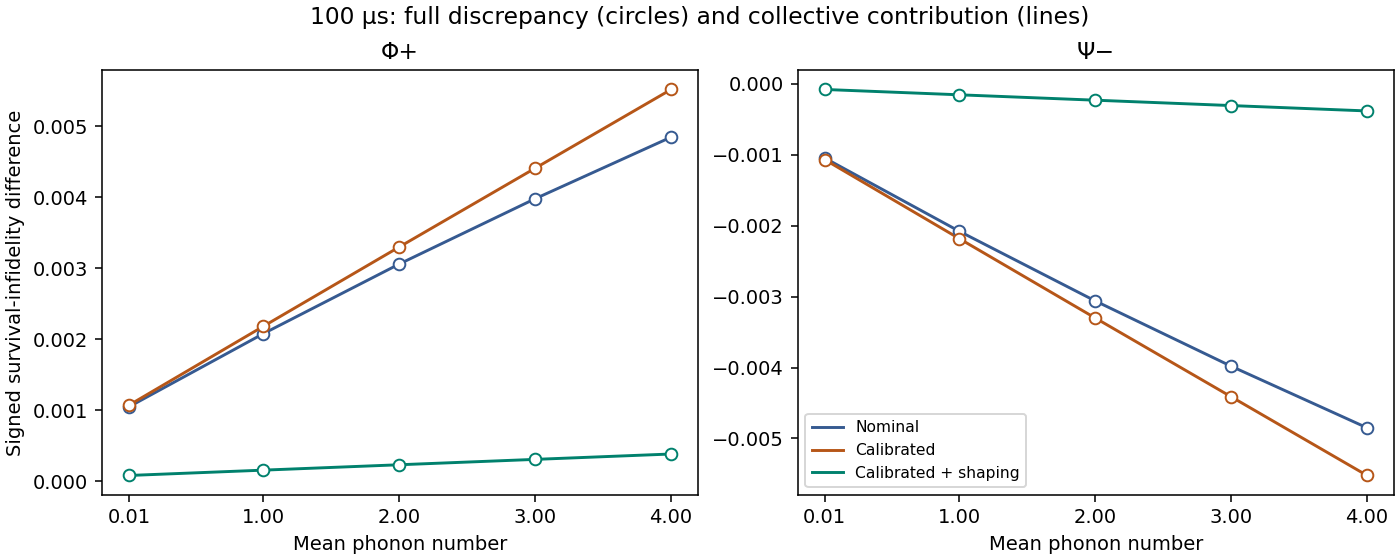

In [4]:
import matplotlib.pyplot as plt

fig_cross, axes_cross = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for condition, color, label in zip(bell_conditions.values(),
        ["#365a91", "#b65618", "#00816d"], ["Nominal", "Calibrated", "Calibrated + shaping"]):
    points = cross_results[cross_results["条件"] == condition].sort_values("n̄")
    for ax, state in zip(axes_cross, ["Φ+", "Ψ−"]):
        ax.plot(points["n̄"], points[f"集団項 {state}"], color=color, label=label)
        ax.scatter(points["n̄"], points[f"δr {state}"], facecolors="white", edgecolors=color, zorder=3)
        ax.set(title=state, xlabel="Mean phonon number", xticks=[0.01, 1, 2, 3, 4])
axes_cross[0].set_ylabel("Signed survival-infidelity difference")
axes_cross[1].legend(fontsize=8)
fig_cross.suptitle("100 µs: full discrepancy (circles) and collective contribution (lines)")
plt.show()

## 100 µs のダイヤモンド距離による Pauli 近似の判定

縦軸は各チャネルとその Pauli twirl のダイヤモンド距離（ダイヤモンドノルムの半分、対数目盛）。点は計算した平均フォノン数、破線は許容幅を示す。表の判定には半正定値計画の数値上下限を用いる。

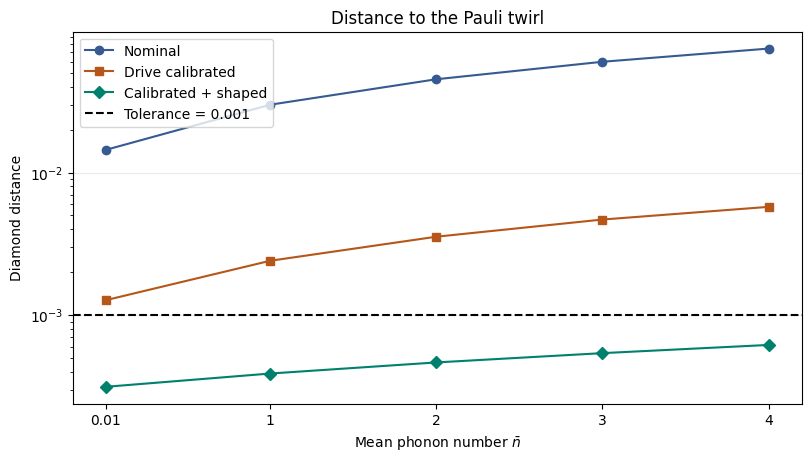

,条件,平均フォノン数,距離推定値,数値下限,数値上限,判定
0,ノーマル,0.01,0.014417329,0.0144173288169,0.0144173288288,範囲外
1,駆動強度校正,0.01,0.0012710758,0.00127107580566,0.00127107580622,範囲外
2,駆動強度校正＋パルス整形,0.01,0.00031353729,0.000313537292304,0.000313537292808,範囲内
3,ノーマル,1,0.029915393,0.0299153933707,0.029915393395,範囲外
4,駆動強度校正,1,0.0024029266,0.00240292659076,0.00240292659196,範囲外
5,駆動強度校正＋パルス整形,1,0.0003885708,0.000388570798069,0.000388570798221,範囲内
6,ノーマル,2,0.045134085,0.045134085137,0.0451340851725,範囲外
7,駆動強度校正,2,0.0035445781,0.00354457811158,0.00354457811303,範囲外
8,駆動強度校正＋パルス整形,2,0.00046490906,0.000464909057104,0.000464909057955,範囲内
9,ノーマル,3,0.059871598,0.0598715975241,0.0598715975704,範囲外


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

diamond_data = pd.read_csv(Path("results/matched_pulse_calibration_sweep/100us/diamond_distances.csv"))
tau, = diamond_data["tolerance"].unique()
styles = {
    "standard_nominal": ("Nominal", "#365a91", "o"),
    "standard": ("Drive calibrated", "#b65618", "s"),
    "smooth_detuning": ("Calibrated + shaped", "#00816d", "D"),
}
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for condition, (label, color, marker) in styles.items():
    points = diamond_data.loc[diamond_data.condition == condition].sort_values("n_bar")
    ax.plot(points.n_bar, points.diamond_distance_estimate,
            label=label, color=color, marker=marker)
ax.axhline(tau, color="black", linestyle="--", label=f"Tolerance = {tau:g}")
ax.set(yscale="log", xlabel=r"Mean phonon number $\bar{n}$",
       ylabel="Diamond distance", title="Distance to the Pauli twirl")
ax.set_xticks([0.01, 1, 2, 3, 4], labels=["0.01", "1", "2", "3", "4"])
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.show()

diamond_table = diamond_data[["condition", "n_bar", "diamond_distance_estimate",
                              "diamond_sdp_lower", "diamond_sdp_upper", "classification"]].copy()
diamond_table.columns = ["条件", "平均フォノン数", "距離推定値", "数値下限", "数値上限", "判定"]
diamond_table["条件"] = diamond_table["条件"].map(dict(zip(styles, ["ノーマル", "駆動強度校正", "駆動強度校正＋パルス整形"])))
diamond_table["判定"] = diamond_table["判定"].map({"within": "範囲内", "outside": "範囲外", "unresolved": "未確定"})
display(diamond_table.style.format({"平均フォノン数": "{:g}", "距離推定値": "{:.8g}",
                                    "数値下限": "{:.12g}", "数値上限": "{:.12g}"}))